# Supplementary figures: explore the data with your own settings

The walkthrough notebook (`walkthrough.ipynb`) tells the story of the pipeline
with a handful of figures. The original thesis repository drew many more:
QC and missingness plots, every PCA loading view, influence plots, the
outlier-ensemble diagnostics, p-value calibration, feature modules, litter
plots and the facility-style figures. This notebook draws them all, and
**recomputes them from the settings cell below**, so you can:

* **remove samples** you consider outliers (or none at all);
* **change the preprocessing thresholds**: prevalence filter, blank filter,
  detection floor, median or PQN normalisation;
* **change analysis choices**: scaling, FDR level, number of PCs for the
  outlier screen, permutation and bootstrap counts;
* switch between **lipidomics, metabolomics and proteomics**.

**How to use it.** Edit the settings cell, then *Kernel → Restart & Run All*.
The defaults reproduce the pipeline's primary analysis: all 60 samples and the
current lipid filtering (features missing in more than 20 % of samples
removed, median signal at least 3 x the blank, no imputation). A full run takes
about one to two minutes, plus two minutes the first time the outlier ensemble
is computed. Every figure states the data it was drawn from in grey
underneath it, so a saved figure always carries its settings.

The figure code lives in `src/mia_multiomics/explore/`. Each figure is one
function that takes a *view* (the preprocessed data plus your settings) and
returns a Matplotlib figure.

| Section | Figures |
|---|---|
| 2 Preprocessing and pooled QC | feature funnel, prevalence curve, signal-to-blank, Tech-Mix CV and drift |
| 3 Missingness | per feature, per sample, by region and group, heatmaps before and after filtering |
| 4 Noise floor | abundance-similarity curves |
| 5 Sample-space PCA | scree (grouped, attributed), scores coloured by every design factor, pooled composite |
| 6 PCA loadings | lollipop, scatter, heatmap, class composition, concentration, top features |
| 7 Outlier screen (your settings) | Hotelling T², DModX, influence plot, T² ellipses, assay concordance |
| 8 Outlier ensemble (all 60) | stability per scope, corroboration, null percentiles |
| 9 Per-feature models | hit counts, volcanoes, p-value calibration, top hits, forest, single feature, lipid classes |
| 10 Feature space | correlation modules, feature view, loading stability, module stability |
| 11 Litters | PCA by cage, cage panels, within-litter spread |
| 12 Regional profiles | region differences in control vs MIA |
| 13 ASCA+ | variance partition and effect scores |
| 14 Facility-style figures | heatmap and PLS-DA with permutation null, every region |
| 15 Lipid vs protein | myelin index against myelin proteins, every region |

## 1. Settings

Change anything here, then restart and run all cells.

*A note on removing samples.* The thesis analyses allow only three
populations: all 60 samples, or the samples flagged by the regional Hotelling T²
screen at 95 % or 99 % removed, and never a whole mouse. This notebook lets you
remove any sample so that you can see what each choice does. The table in the
next section lists the T²-flagged samples, and a warning is printed if you
remove every region of a mouse.

In [1]:
# ---- data -------------------------------------------------------------------------
OMICS = "lipidomics"            # "lipidomics", "metabolomics" or "proteomics"
EXCLUDE = []                    # samples to remove: sample numbers, e.g. [10, 45], or IDs, e.g. ["TOY_001-10"]

# ---- preprocessing thresholds (lipidomics and metabolomics) ------------------------
MAX_MISSING_FRACTION = 0.20     # drop features missing in more than this share of all 60 samples (None = off)
BLANK_MULTIPLIER = 3.0          # blank filter and detection limit: multiple of the mean blank signal
DETECTION_FLOOR = None          # None = default (1.0 for lipids, smallest positive value for metabolites)
NORMALIZATION = "median"        # "median" or "pqn"

# ---- analysis choices ---------------------------------------------------------------
SCALING = "autoscaled"          # "autoscaled", "pareto" or "unscaled": PCA, outlier screen, heatmaps, ASCA
FDR_ALPHA = 0.05                # Benjamini-Hochberg level for "hits"
MIN_PER_CELL = 3                # a feature is modelled only with >= this many values in every group x sex cell
OUTLIER_PCS = 3                 # principal components used for Hotelling T2 and DModX
TOP_N = 20                      # features shown in loading and forest plots
N_PERMUTATIONS = 199            # PLS-DA permutation test
N_BOOTSTRAPS = 100              # loading and module stability

# ---- what to show -------------------------------------------------------------------
REGION = "Cortex"               # region of the single-region figures: "Cerebellum", "Cortex" or "Hippocampus"
EFFECT = "MIA vs Saline Control"  # or "Female vs Male", "MIA x Female interaction"
FEATURE = None                  # one feature to profile, e.g. "Cer(d18:0_14:0)"; None = the top hit of EFFECT in REGION
SAVE_FIGURES = True            # True: also write every figure as PNG to results/supplementary/<run name>/

In [2]:
import io, re, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))           # not needed after `pip install -e .`

from mia_multiomics import config, explore, plotting
from mia_multiomics.config import Settings
from mia_multiomics.toy_data import write_toy_dataset

settings = Settings.fast(PROJECT)
if not (settings.data_dir / config.REPORT_WORKBOOK).exists():
    write_toy_dataset(settings.data_dir)            # the simulated data, if not written yet
plotting.apply_plot_style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)

options = explore.Options(
    omics=OMICS, exclude=EXCLUDE, max_missing_fraction=MAX_MISSING_FRACTION, blank_multiplier=BLANK_MULTIPLIER,
    detection_floor=DETECTION_FLOOR, normalization=NORMALIZATION, scaling=SCALING, fdr_alpha=FDR_ALPHA,
    min_per_cell=MIN_PER_CELL, outlier_pcs=OUTLIER_PCS, top_n=TOP_N, n_permutations=N_PERMUTATIONS,
    n_bootstraps=N_BOOTSTRAPS)
view = explore.build_view(settings, options)

FIGURES = {}                                        # every figure drawn, as PNG bytes, for optional saving

def draw(function, *args, **kwargs):
    """Draw one figure inline. A figure that does not apply to these settings prints why instead."""
    try:
        fig = function(*args, **kwargs)
    except ValueError as error:
        print(f"skipped {function.__name__}: {error}")
        return
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=100, bbox_inches="tight")
    plt.close(fig)
    labels = [str(a) for a in [*args, *kwargs.values()] if a is not None and not isinstance(a, (explore.View, explore.EnsembleResults))]
    name = re.sub(r"[^A-Za-z0-9_.]+", "-", "_".join([function.__name__, *labels])).strip("-")
    FIGURES[name] = buffer.getvalue()
    display(Image(buffer.getvalue()))

print(view.tag())
for mouse in view.removed_whole_mice():
    print(f"WARNING: every region of mouse {mouse} is excluded - the thesis analyses never remove a whole mouse.")
display(view.summary())
display(view.cell_counts())

lipidomics | 60 samples | prevalence <= 20% missing | blank x3 | median | 282 features | autoscaled


,value
omics,lipidomics
n_samples,60
n_features_input,301
n_after_prevalence,288
n_blank_dominated,6
n_no_detectable_value,0
n_features_output,282
n_values_below_detection,161
detection_floor,1.0
blank_multiplier,3.0


Bio group      MIA      Saline Control     
Sex         Female Male         Female Male
Sample type                                
Cerebellum       5    5              5    5
Cortex           5    5              5    5
Hippocampus      5    5              5    5

Which samples does the regional Hotelling T² screen flag? The screen uses all 60
samples with the default preprocessing, because outliers have to be found
before anything is removed. At 95 %, these are the samples of the `t2_95`
population; those that also exceed the 99 % limit form `t2_99`.

In [3]:
explore.suggest_exclusions(settings, OMICS, level=0.95)

,Sample number,Sample,Region,Mouse number,Bio group,Sex,hotelling_t2,hotelling_t2_95_limit,normalized_dmodx,normalized_dmodx_95_flag
0,2,TOY_001-02,Cerebellum,C10001 - 1,Saline Control,Male,8.421,6.82,0.851,False
1,10,TOY_001-10,Cortex,C20001 - 2,MIA,Male,17.817,6.82,0.137,False
2,24,TOY_001-24,Hippocampus,C20002 - 2,MIA,Male,7.473,6.82,0.828,False
3,45,TOY_001-45,Hippocampus,C10002 - 2,Saline Control,Male,17.828,6.82,0.126,False


## 2. Preprocessing and pooled QC

How many features each filter removes, and how the thresholds were chosen.
Prevalence and the blank filter are judged on all 60 raw samples, so every
population sees the same feature panel. The Tech-Mix is one pooled sample
injected six times; its CV measures technical reproducibility (reported, never
used as a filter).

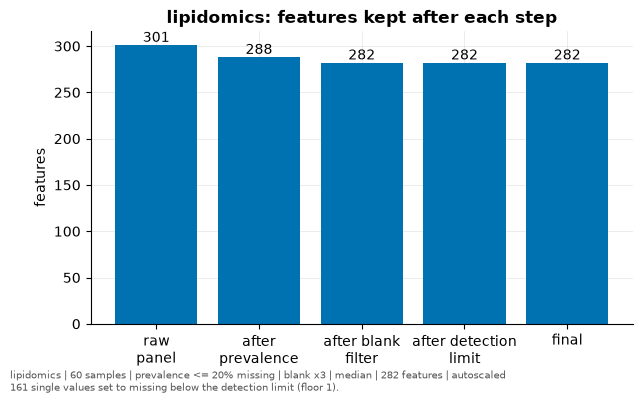

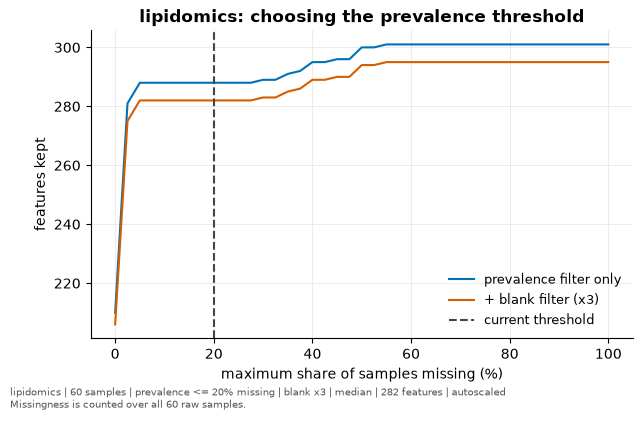

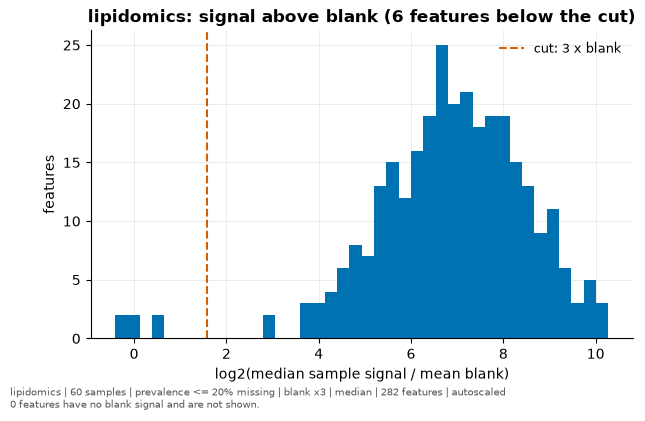

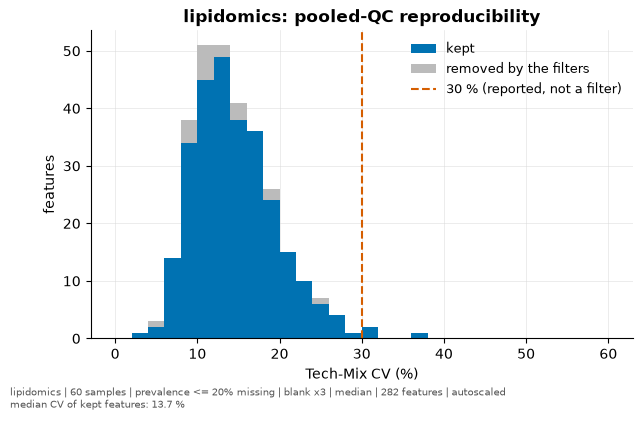

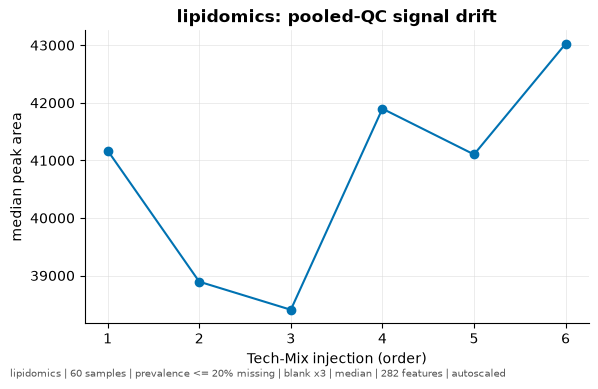

In [4]:
draw(explore.feature_funnel, view)
draw(explore.prevalence_curve, view)
draw(explore.signal_to_blank, view)
draw(explore.techmix_cv, view)
draw(explore.techmix_drift, view)

## 3. Missingness

Missing values are never imputed in the main analysis. Do they cluster in
particular samples, regions, groups or lipid classes? The two heatmaps show the
delivered panel and the data after preprocessing (the detection limit adds
missing values; the prevalence filter removes the emptiest features).

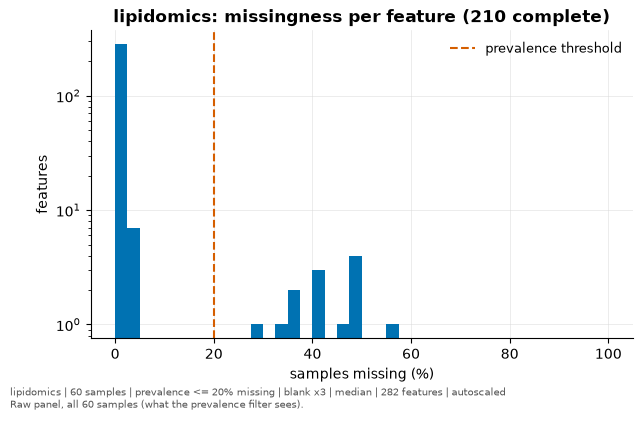

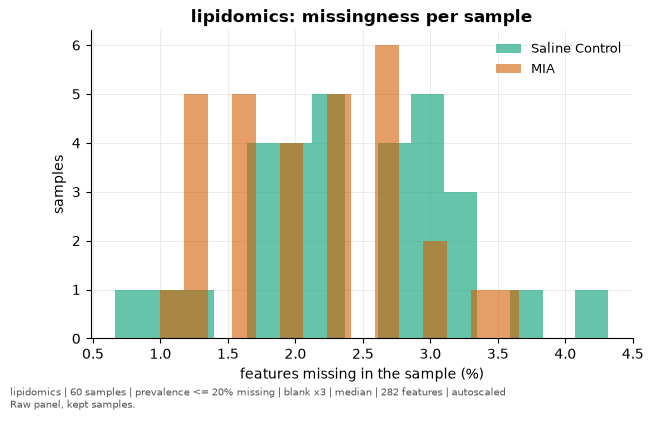

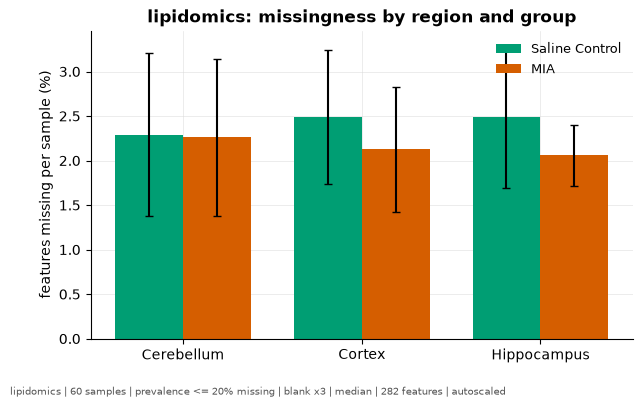

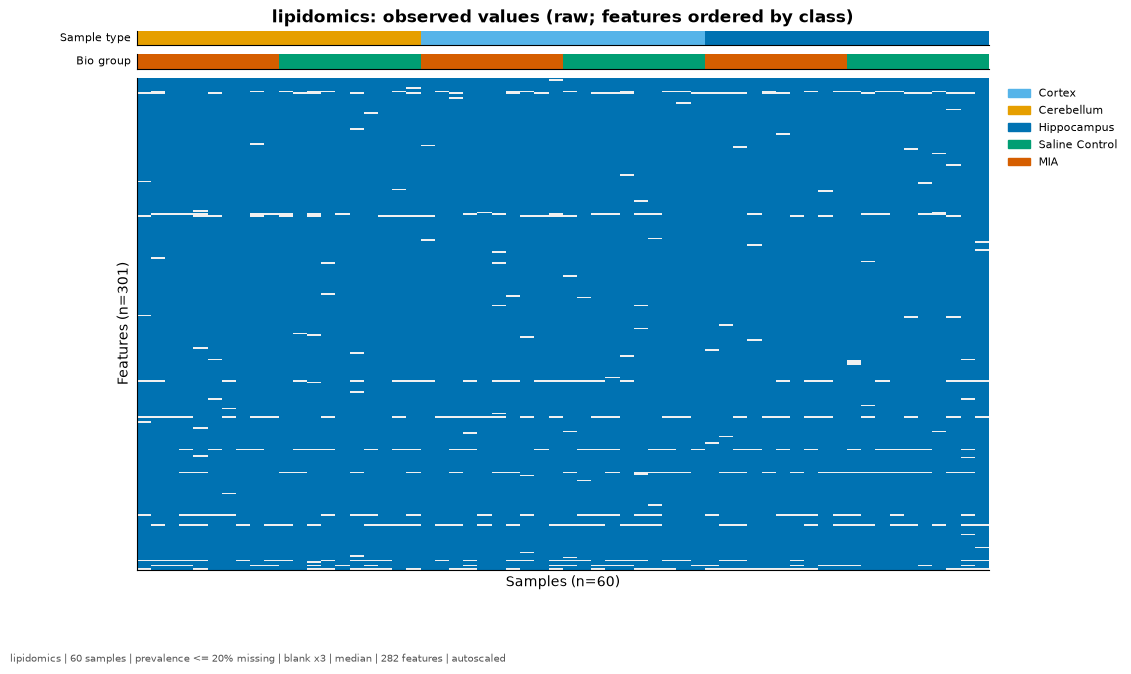

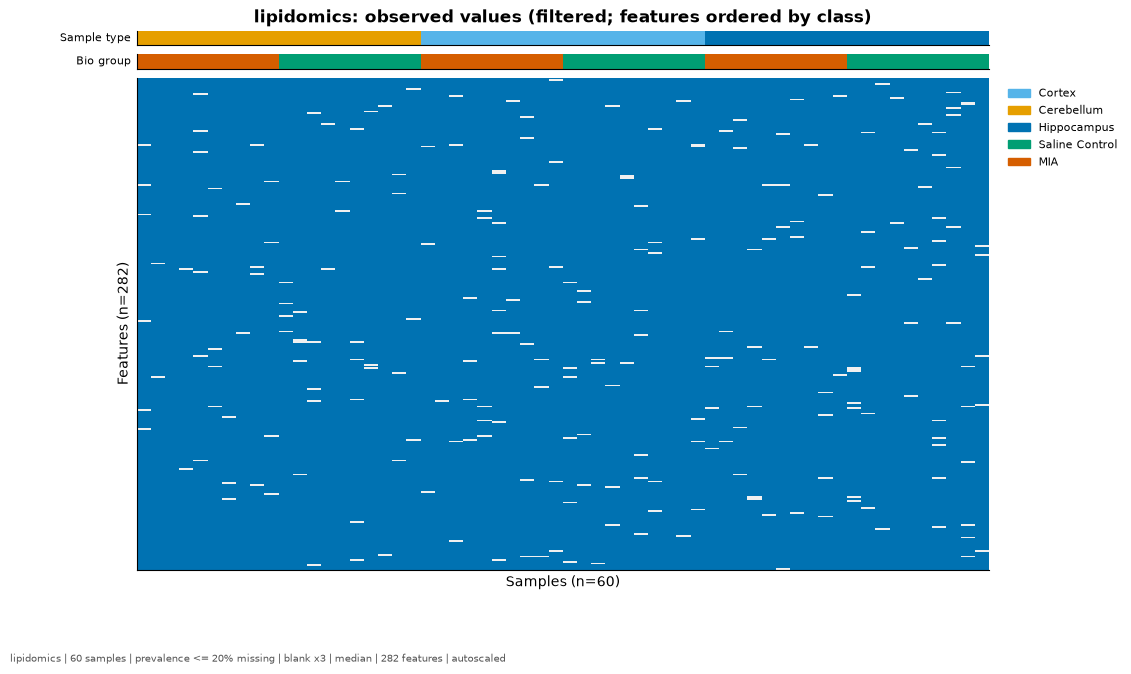

In [5]:
draw(explore.missingness_per_feature, view)
draw(explore.missingness_per_sample, view)
draw(explore.missingness_by_region_and_group, view)
draw(explore.missingness_heatmap, view, stage="raw")
draw(explore.missingness_heatmap, view, stage="filtered")

## 4. Noise floor

noisyR-style abundance-similarity curve. Features are sorted by abundance and
cut into sliding windows, and samples are correlated within each window. At
low abundance (noise) samples agree poorly; the dashed Tech-Mix curve is the
purely technical reference. Candidate thresholds are reported, never applied.

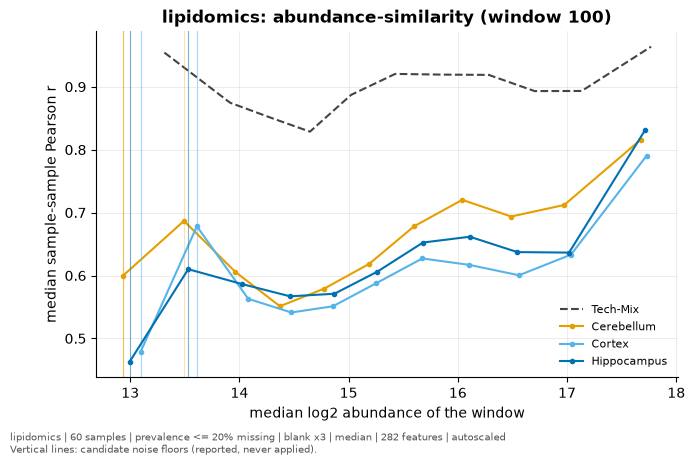

In [6]:
draw(explore.abundance_similarity, view)

## 5. Sample-space PCA

PCA of complete features, scaled as chosen. *Pooled* uses all kept samples,
where region dominates; the regional PCAs show what remains within a region.
The attribution plot splits each component's variance by the design factor
its scores track (marginal R²; factors overlap).

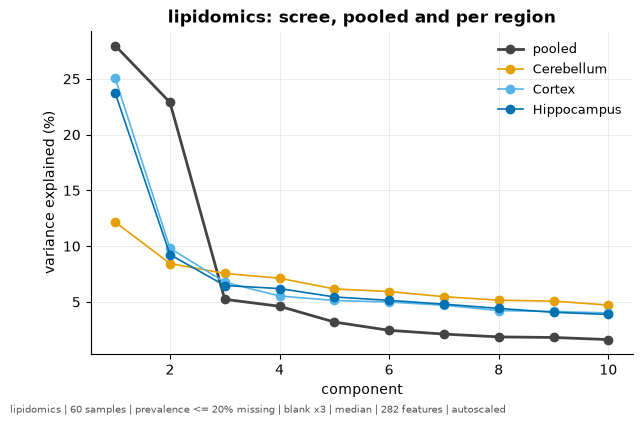

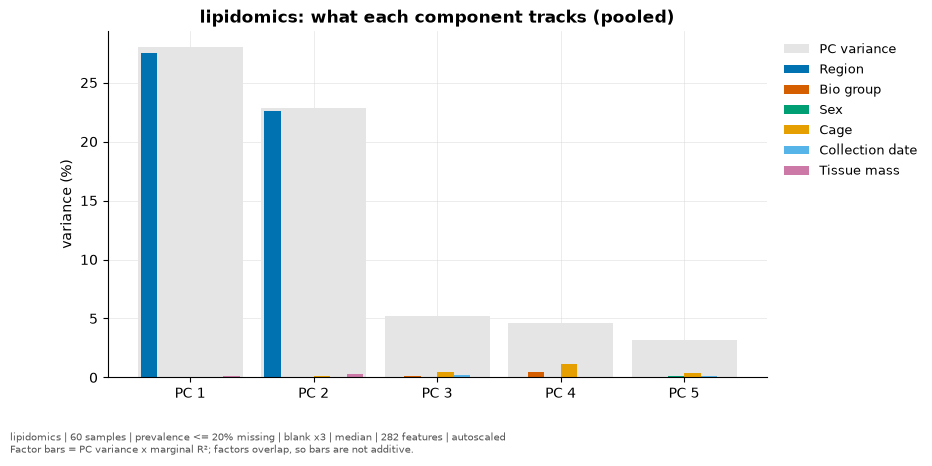

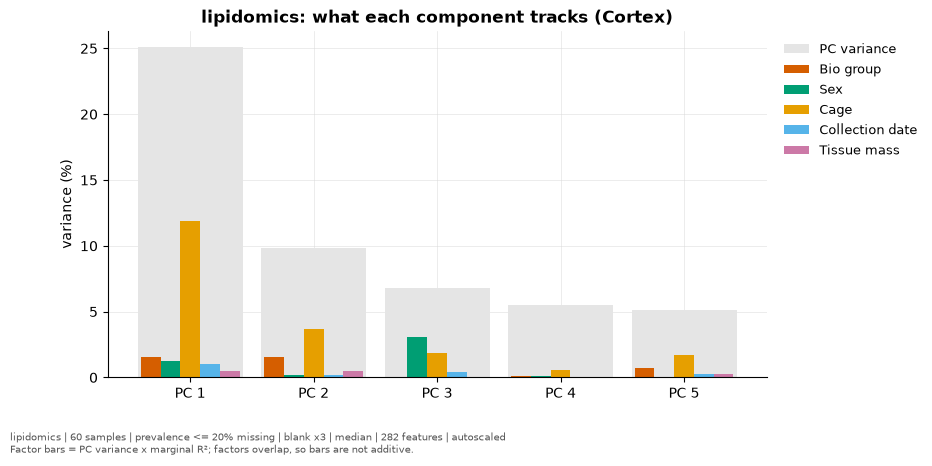

In [7]:
draw(explore.scree_grouped, view)
draw(explore.scree_attribution, view, "pooled")
draw(explore.scree_attribution, view, REGION)

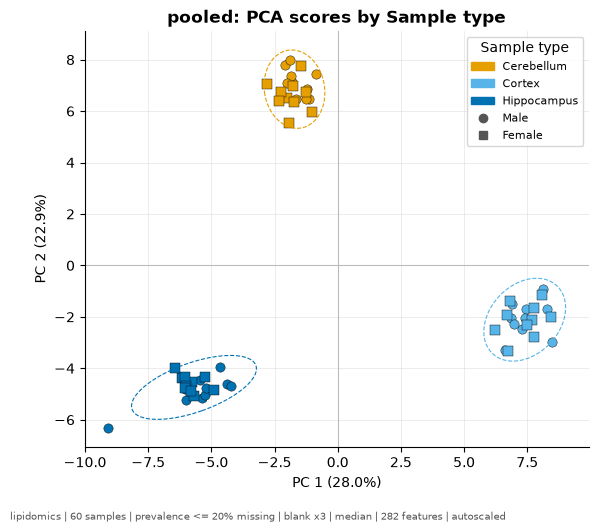

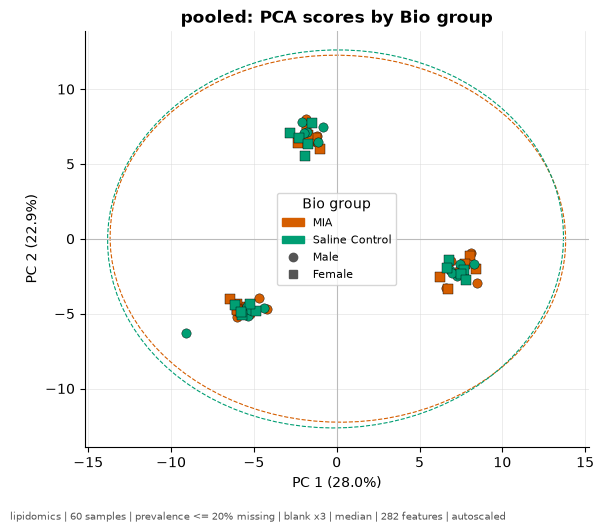

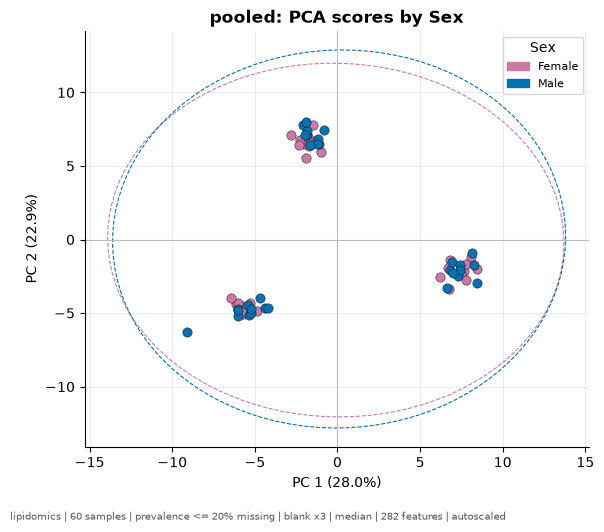

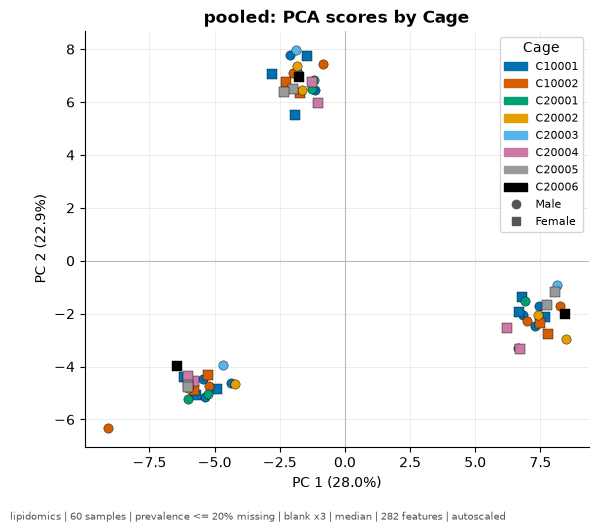

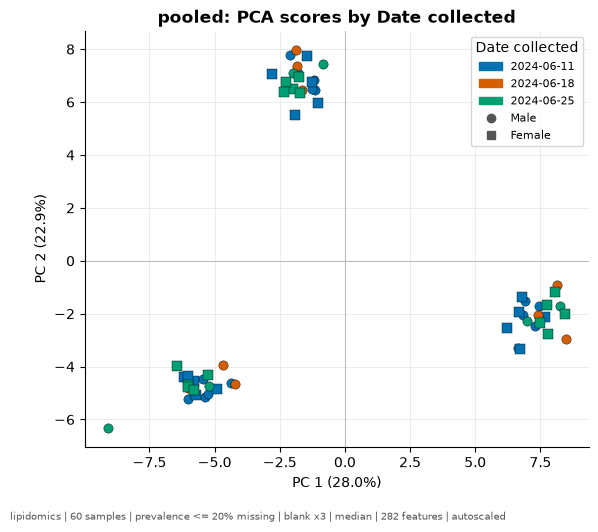

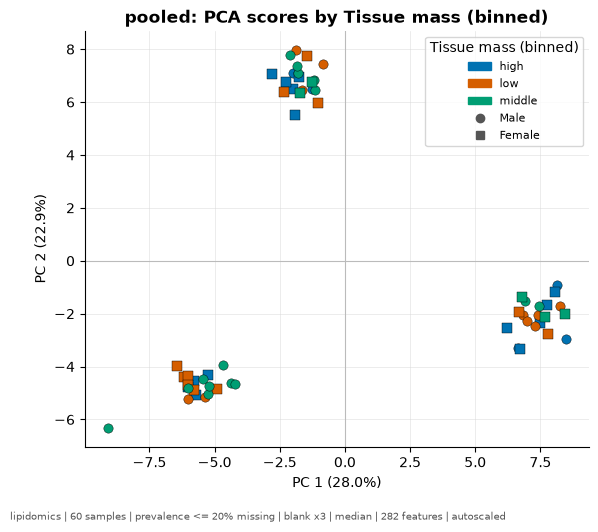

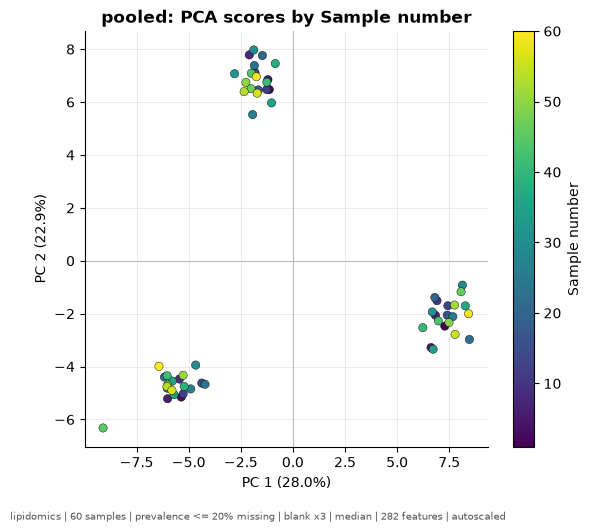

In [8]:
for column in ["Sample type", "Bio group", "Sex", "Cage", "Date collected", "Tissue mass (binned)", "Sample number"]:
    draw(explore.pca_scores, view, "pooled", column)

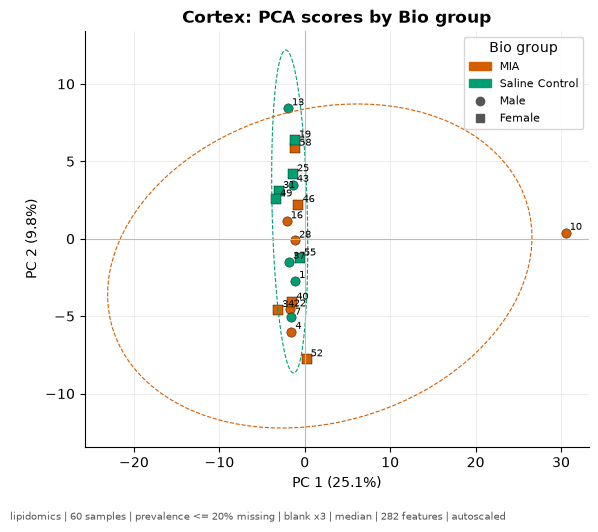

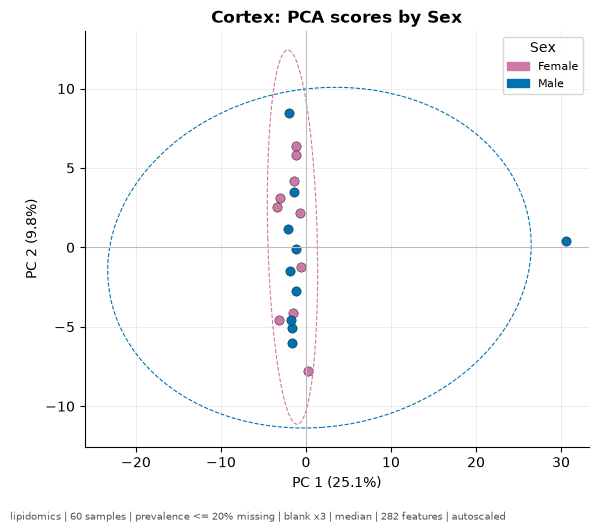

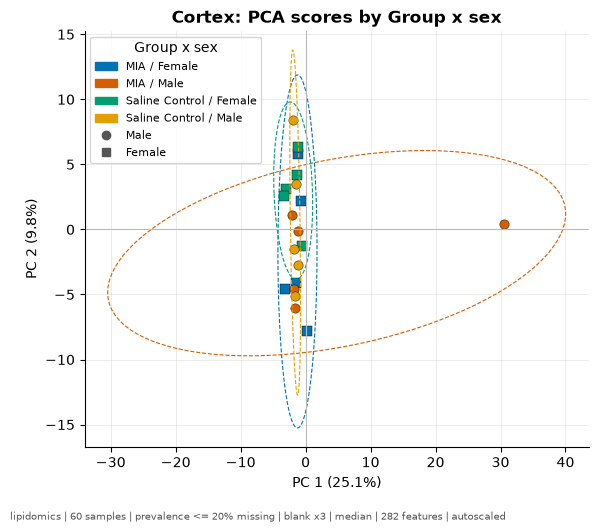

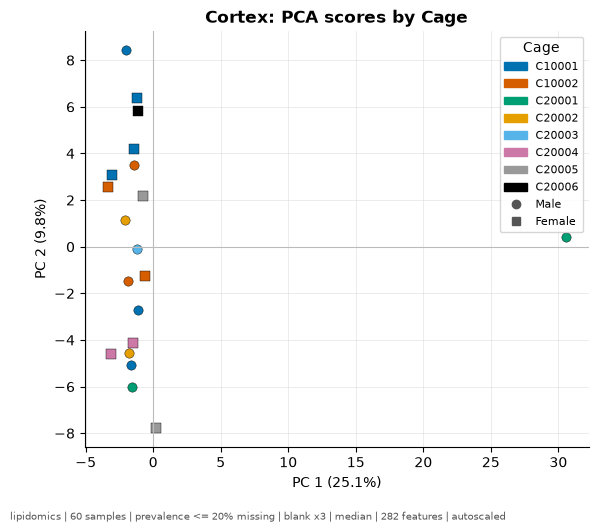

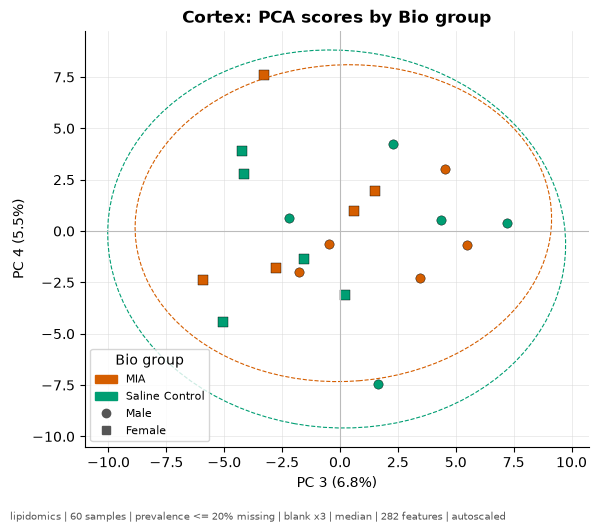

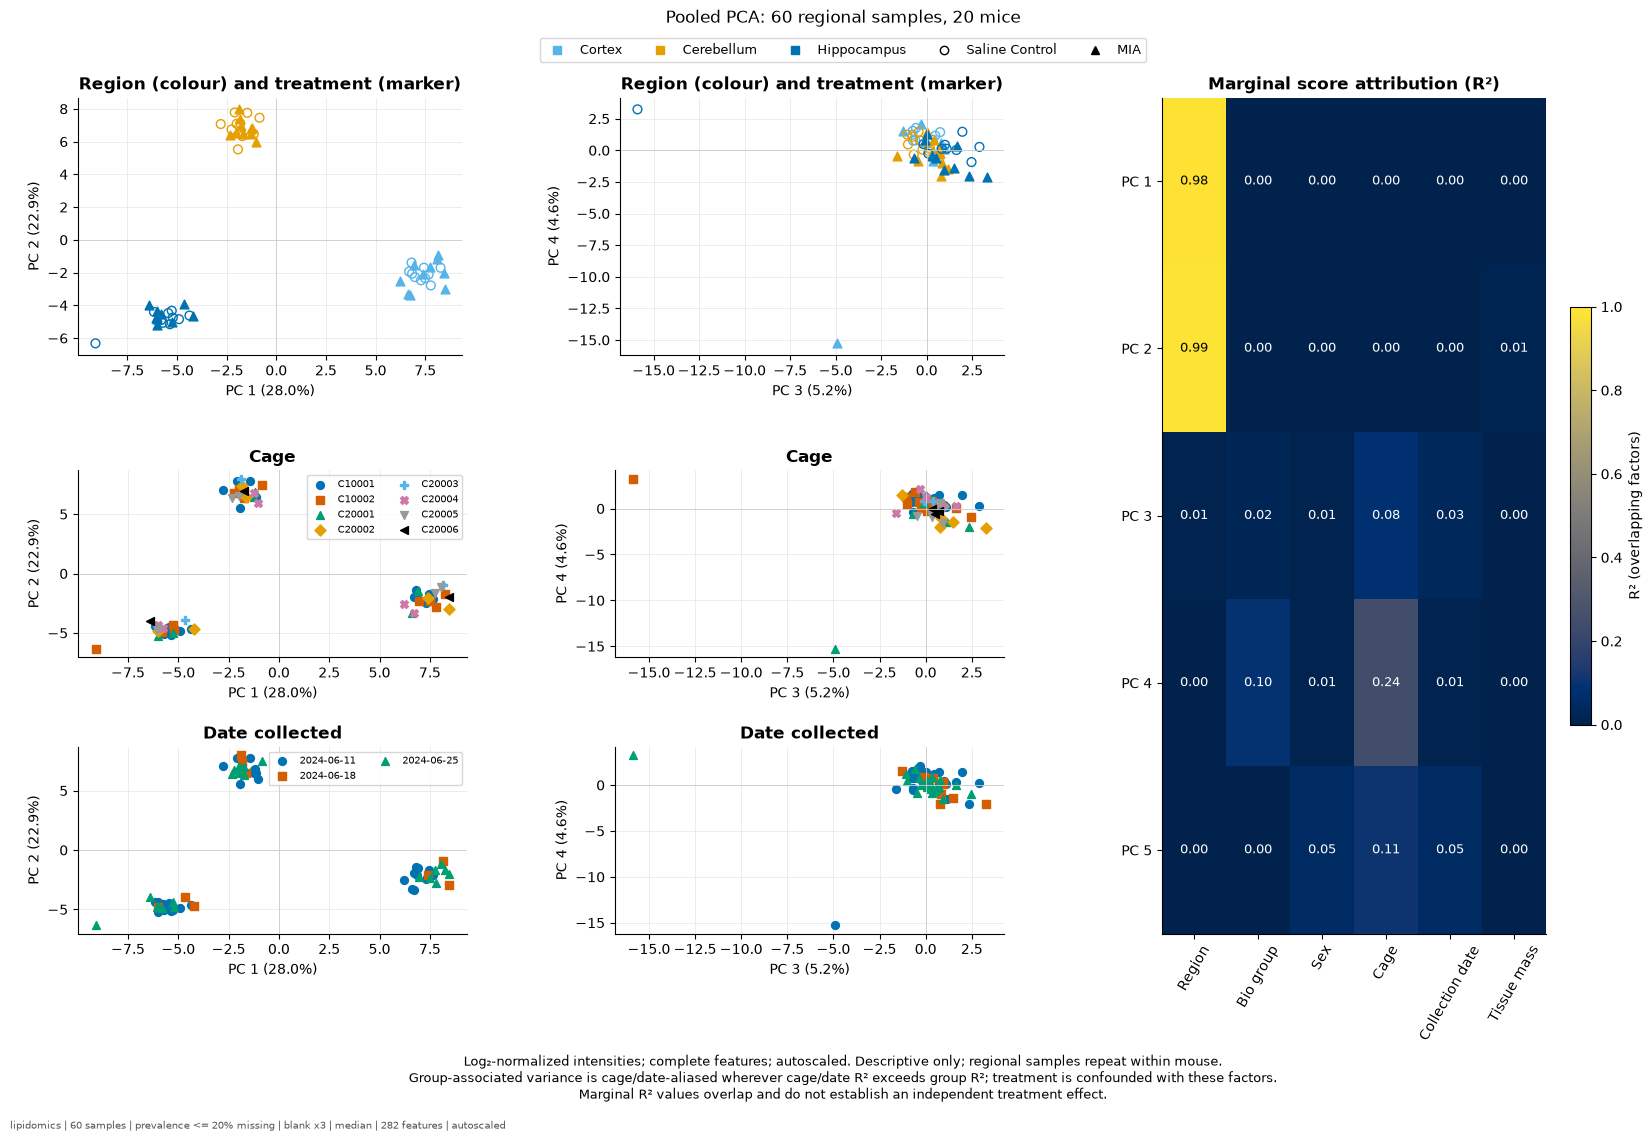

In [9]:
for column in ["Bio group", "Sex", "Group x sex", "Cage"]:
    draw(explore.pca_scores, view, REGION, column, label="Sample number" if column == "Bio group" else None)
draw(explore.pca_scores, view, REGION, "Bio group", x="PC 3", y="PC 4")
draw(explore.region_group_composite, view)

## 6. PCA loadings

Which features drive each component, and are the components carried by a few
features or spread over many? Change `LOADING_SCOPE` to `"pooled"` or a region.

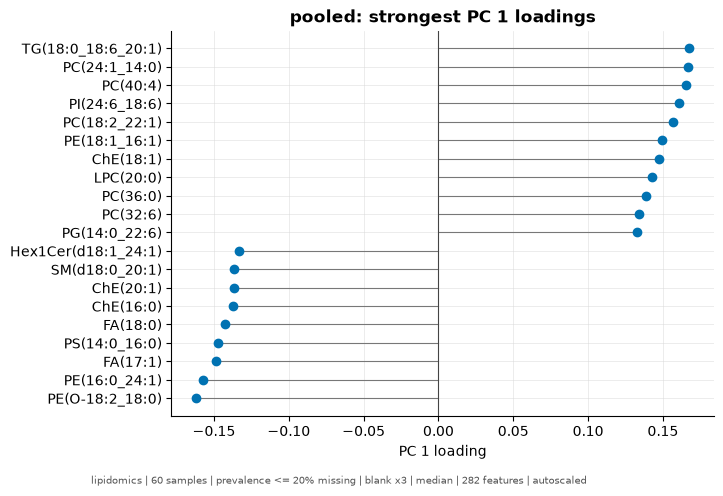

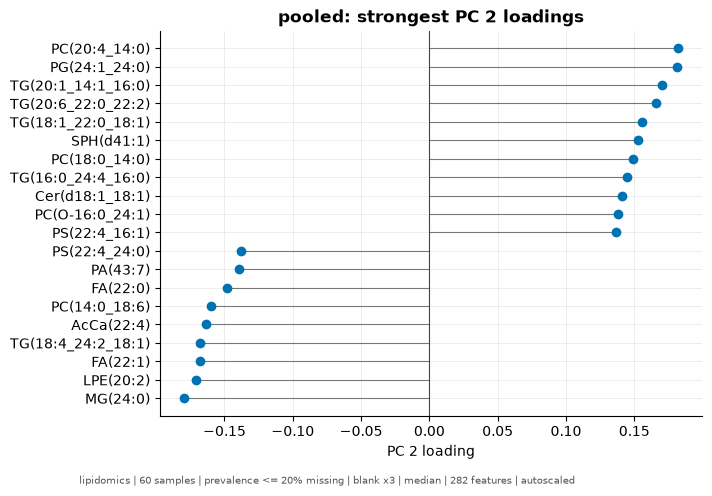

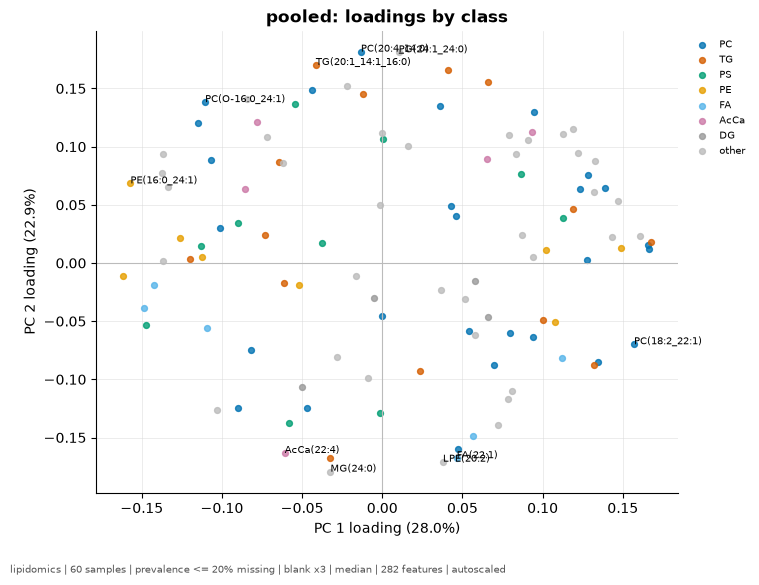

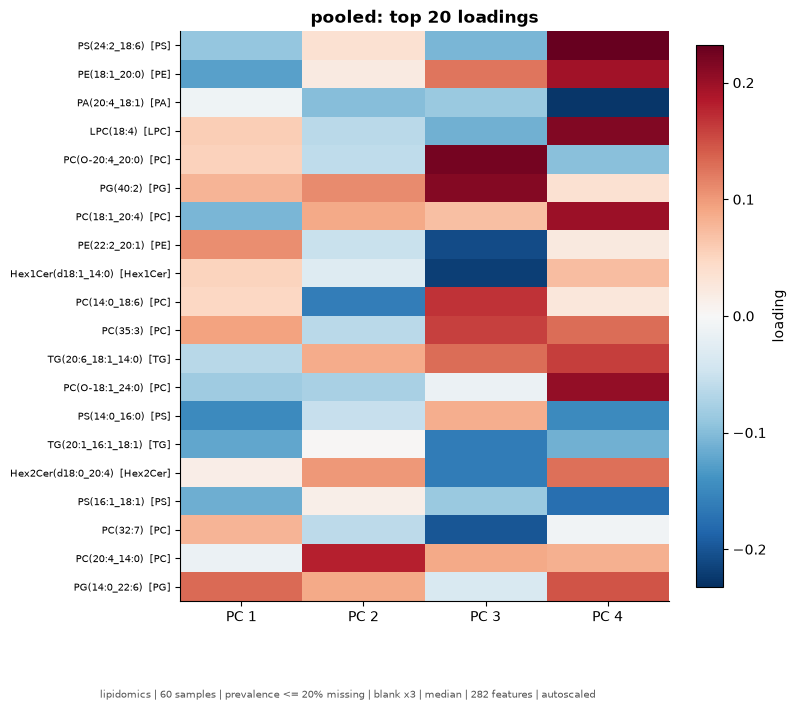

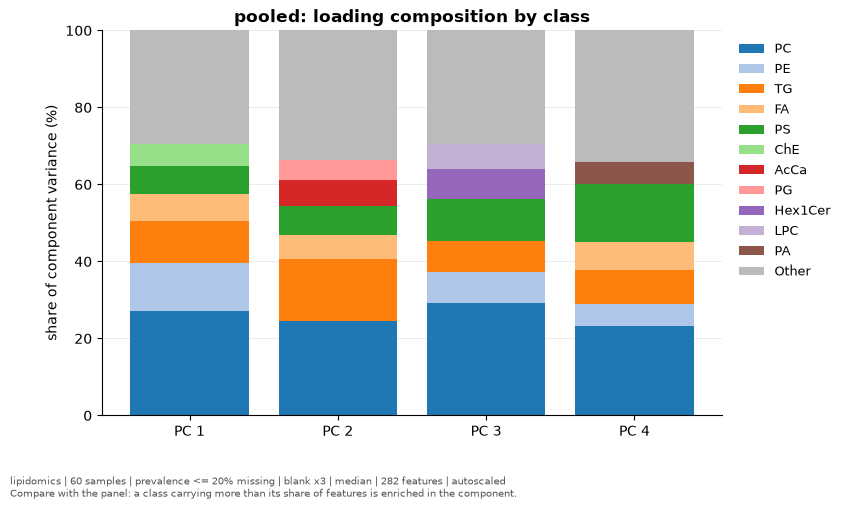

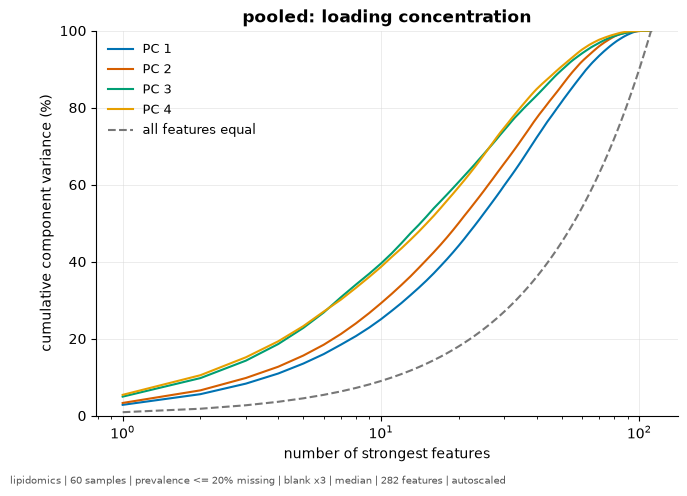

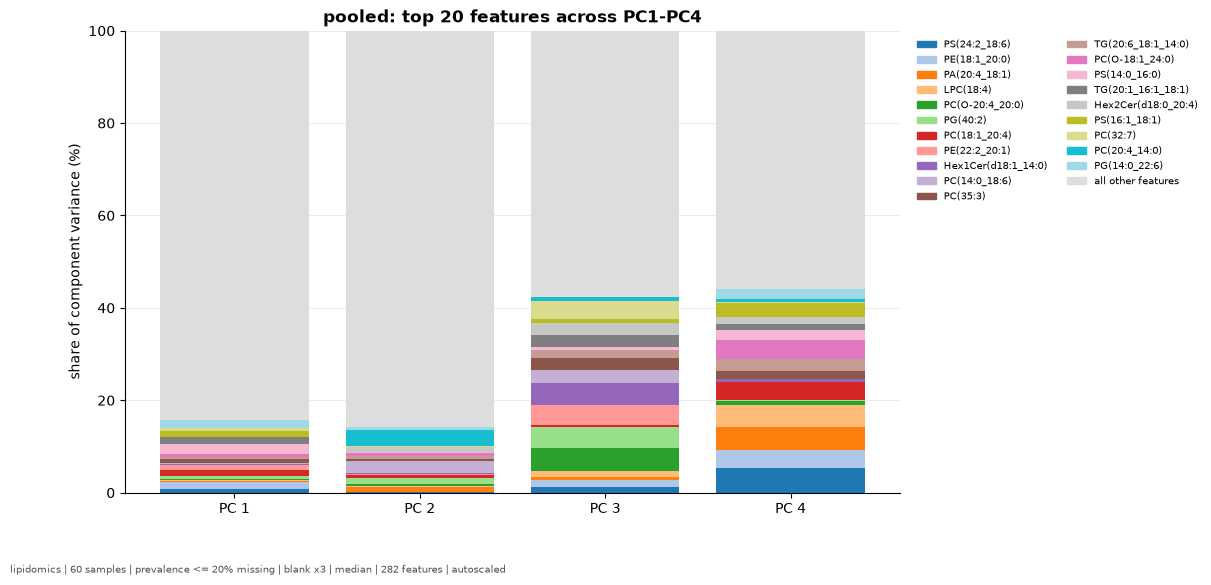

In [10]:
LOADING_SCOPE = "pooled"
draw(explore.loadings_lollipop, view, LOADING_SCOPE, "PC 1")
draw(explore.loadings_lollipop, view, LOADING_SCOPE, "PC 2")
draw(explore.loadings_scatter, view, LOADING_SCOPE)
draw(explore.loadings_heatmap, view, LOADING_SCOPE)
draw(explore.loadings_class_composition, view, LOADING_SCOPE)
draw(explore.loadings_cumulative_share, view, LOADING_SCOPE)
draw(explore.loadings_top_features, view, LOADING_SCOPE)

## 7. Outlier screen with your settings

The regional T²/DModX screen recomputed on *your* samples and thresholds.
Excluding one sample can make another stand out, because the limits are
re-estimated. T² says a sample is extreme *within* the PCA model; DModX says the
model describes it badly. The concordance matrix asks whether lipidomics and
metabolomics flag the same samples. They share one tissue extract, so
agreement is not independent evidence.

,Sample number,Mouse number,Bio group,Sex,hotelling_t2,hotelling_t2_95_limit,hotelling_t2_99_limit,normalized_dmodx,dmodx_95_limit
20,10,C20001 - 2,MIA,Male,17.817,6.82,8.99,0.137,1.083
26,13,C10001 - 3,Saline Control,Male,4.901,6.82,8.99,0.917,1.083
25,1,C10001 - 1,Saline Control,Male,4.041,6.82,8.99,0.918,1.083
28,4,C20001 - 1,MIA,Male,3.931,6.82,8.99,1.020,1.083
21,34,C20004 - 1,MIA,Female,3.684,6.82,8.99,0.942,1.083
29,19,C10001 - 4,Saline Control,Female,3.267,6.82,8.99,1.010,1.083
24,52,C20005 - 2,MIA,Female,3.110,6.82,8.99,1.023,1.083
23,31,C10001 - 6,Saline Control,Female,2.445,6.82,8.99,1.101,1.083


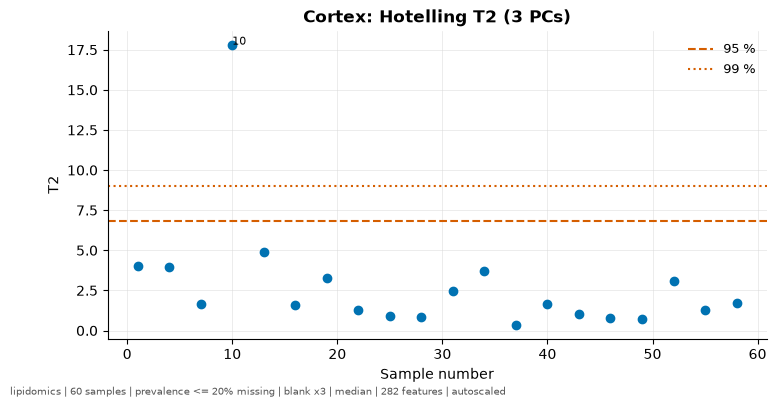

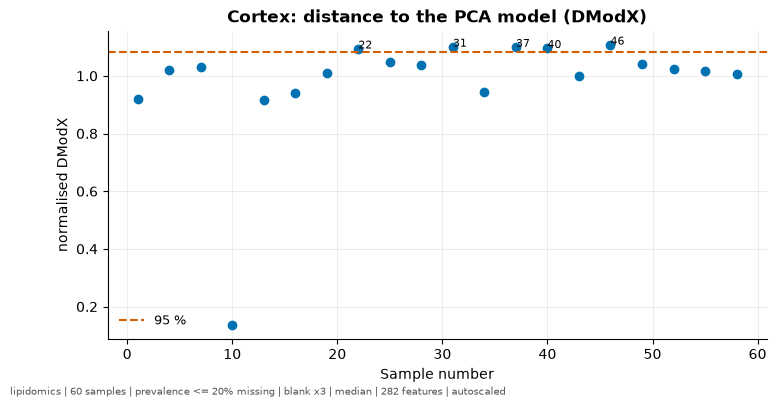

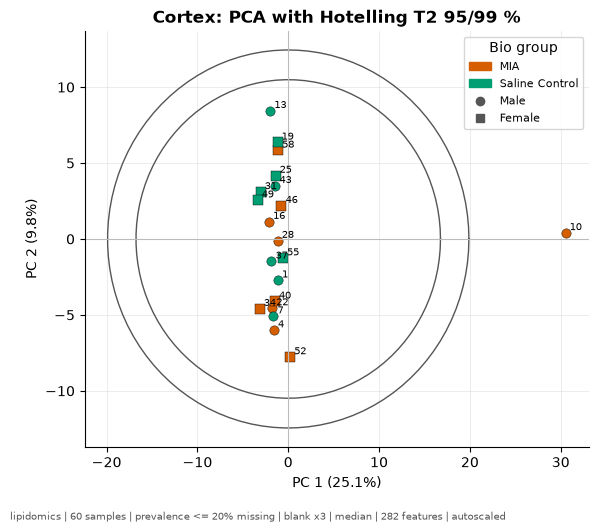

In [11]:
screen = explore.outlier_table(view)
display(screen.loc[screen["Region"].eq(REGION), ["Sample number", config.MOUSE_COL, "Bio group", "Sex", "hotelling_t2",
        "hotelling_t2_95_limit", "hotelling_t2_99_limit", "normalized_dmodx", "dmodx_95_limit"]].sort_values("hotelling_t2", ascending=False).head(8))
draw(explore.t2_plot, view, REGION)
draw(explore.dmodx_plot, view, REGION)
draw(explore.pca_hotelling, view, REGION)

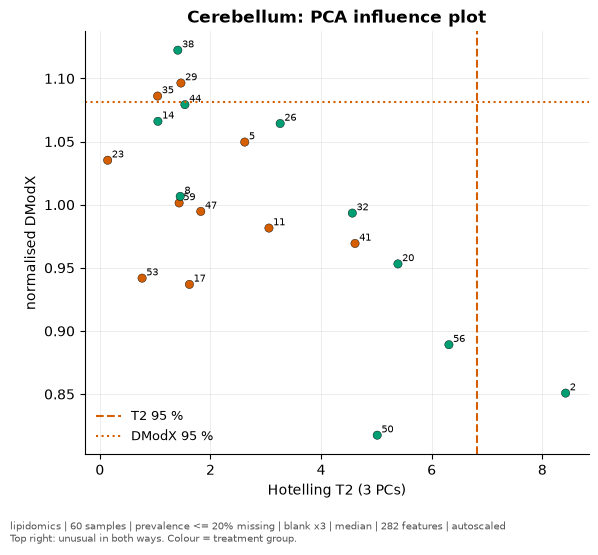

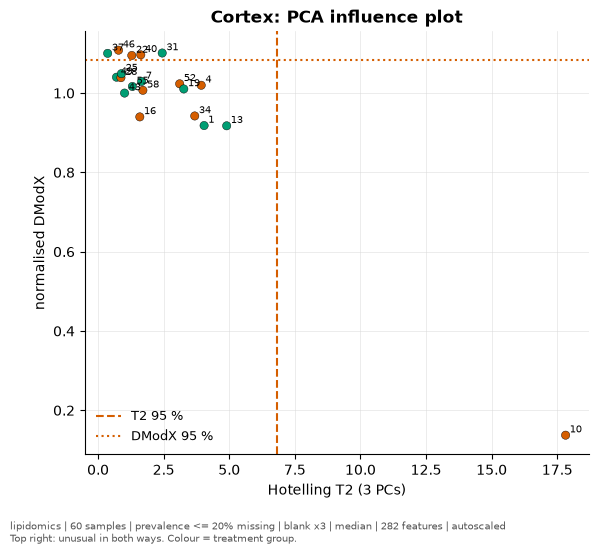

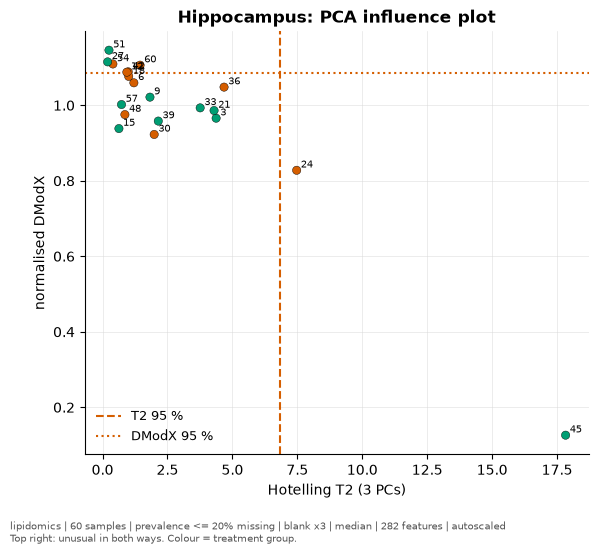

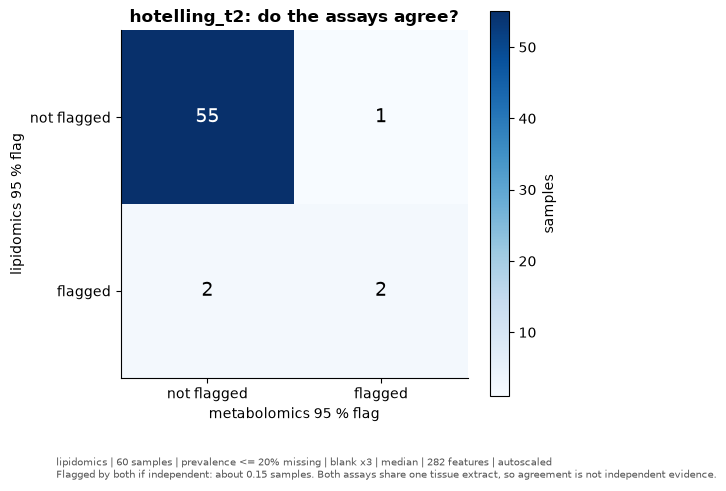

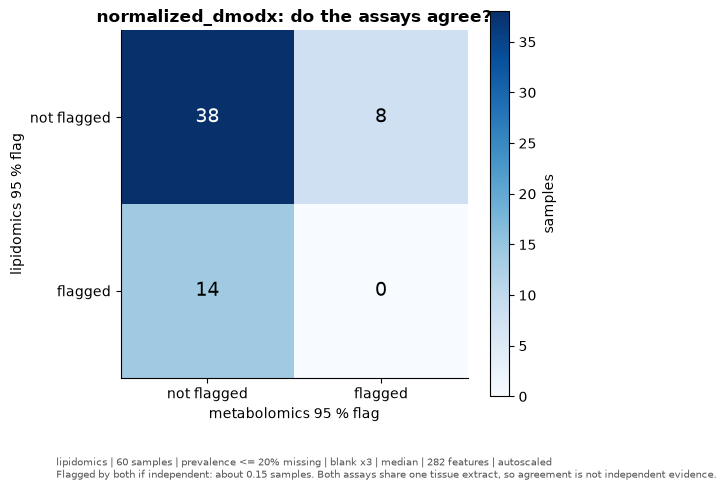

In [12]:
for region in config.REGIONS:
    draw(explore.influence_plot, view, region)
draw(explore.outlier_concordance, view, "hotelling_t2")
draw(explore.outlier_concordance, view, "normalized_dmodx")

## 8. Calibrated outlier ensemble (all 60 samples)

Six detector families, every parameter swept, each setting calibrated against
simulated outlier-free data. A detector *stably* flags a sample when at least
60 % of its settings flag it. A sample is a candidate when at least two
detectors, one of them not covariance-based, stably flag it. Like the T² table
above, this always uses all 60 samples. The tables come from `results/` if the
pipeline or walkthrough has run; otherwise they are computed here (about two
minutes).

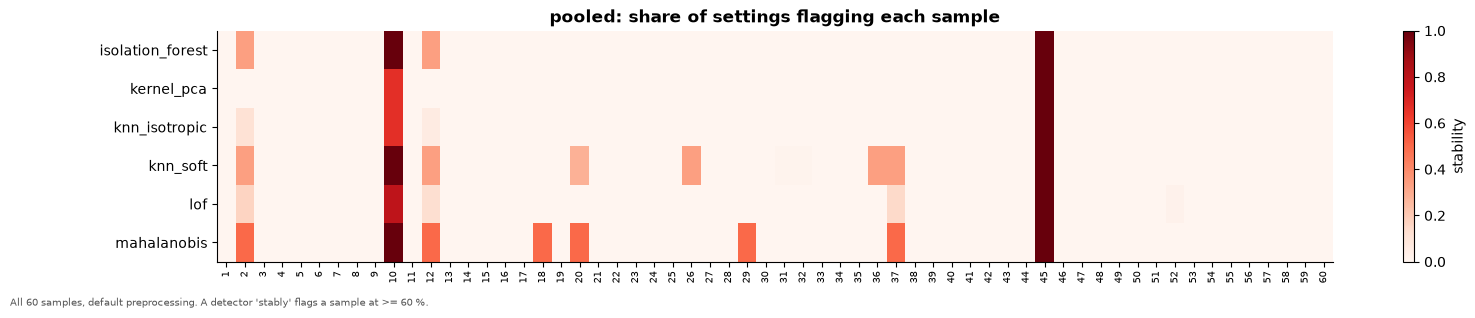

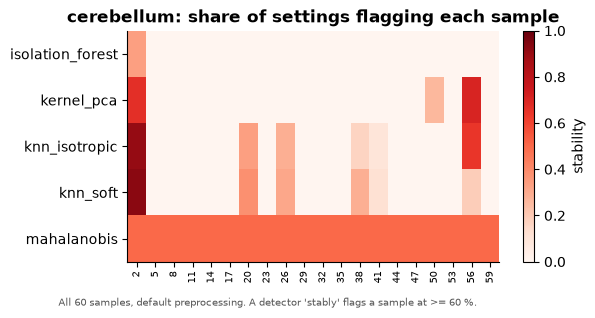

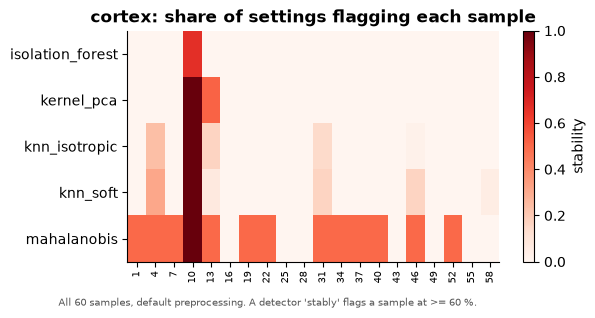

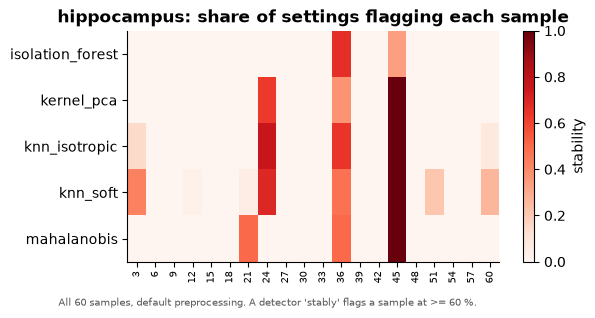

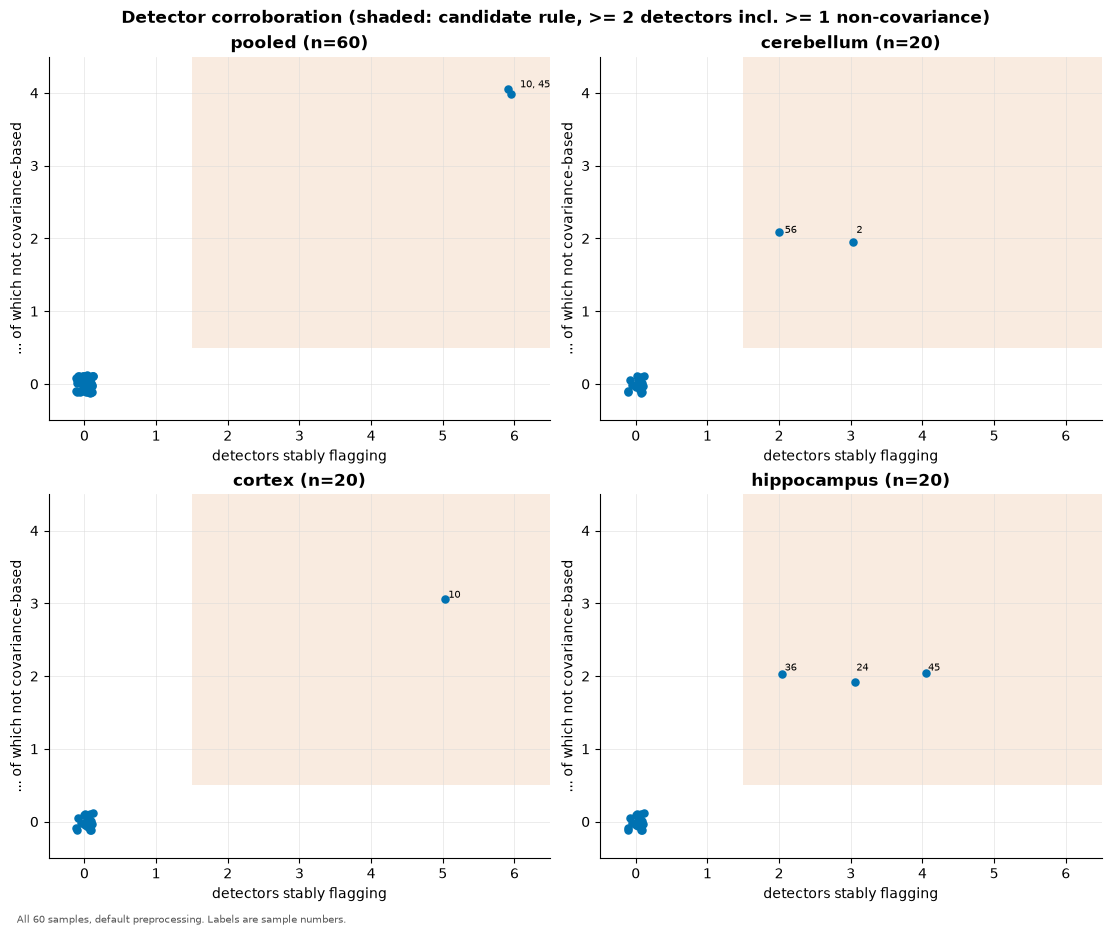

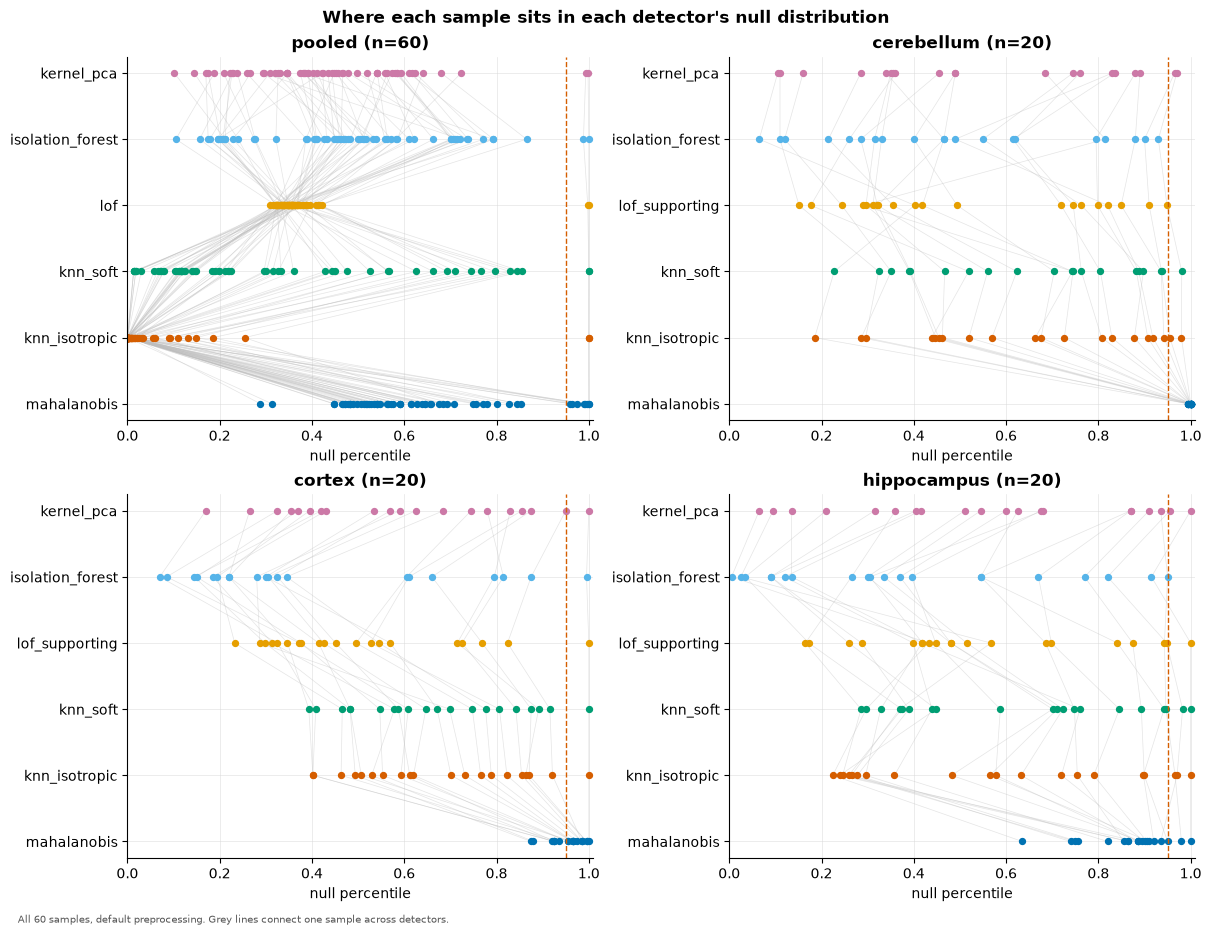

In [13]:
ensemble = explore.ensemble_results(settings, OMICS)
for scope in ["pooled", *[r.lower() for r in config.REGIONS]]:
    draw(explore.ensemble_stability, ensemble, scope)
draw(explore.ensemble_corroboration, ensemble)
draw(explore.ensemble_percentiles, ensemble)

## 9. Per-feature models

`log2 abundance ~ group * sex`, fitted per feature within each region, with
Benjamini-Hochberg FDR over the whole panel. Under no effect the p-values are
flat and the small-p counts match chance. Try the ceramide example from the
walkthrough: `EFFECT = "Female vs Male"`, `REGION = "Cortex"`,
`FEATURE = "Cer(d18:0_14:0)"`, with and without `EXCLUDE = [10, 45]`.

In [14]:
explore.hit_counts(view)

,Region,Effect,n_tested,n_fdr_hits,smallest_q,n_p_below_0_01,expected_p_below_0_01
0,Cerebellum,Female vs Male,282,0,0.053,8,2.82
1,Cerebellum,MIA vs Saline Control,282,0,0.346,5,2.82
2,Cerebellum,MIA x Female interaction,282,0,0.937,2,2.82
3,Cortex,Female vs Male,282,0,0.648,3,2.82
4,Cortex,MIA vs Saline Control,282,0,0.713,1,2.82
5,Cortex,MIA x Female interaction,282,0,0.712,1,2.82
6,Hippocampus,Female vs Male,282,0,0.054,5,2.82
7,Hippocampus,MIA vs Saline Control,282,0,0.452,4,2.82
8,Hippocampus,MIA x Female interaction,282,0,0.702,3,2.82


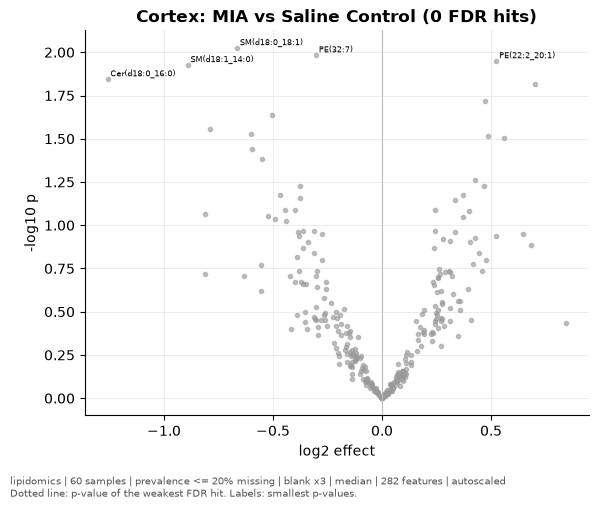

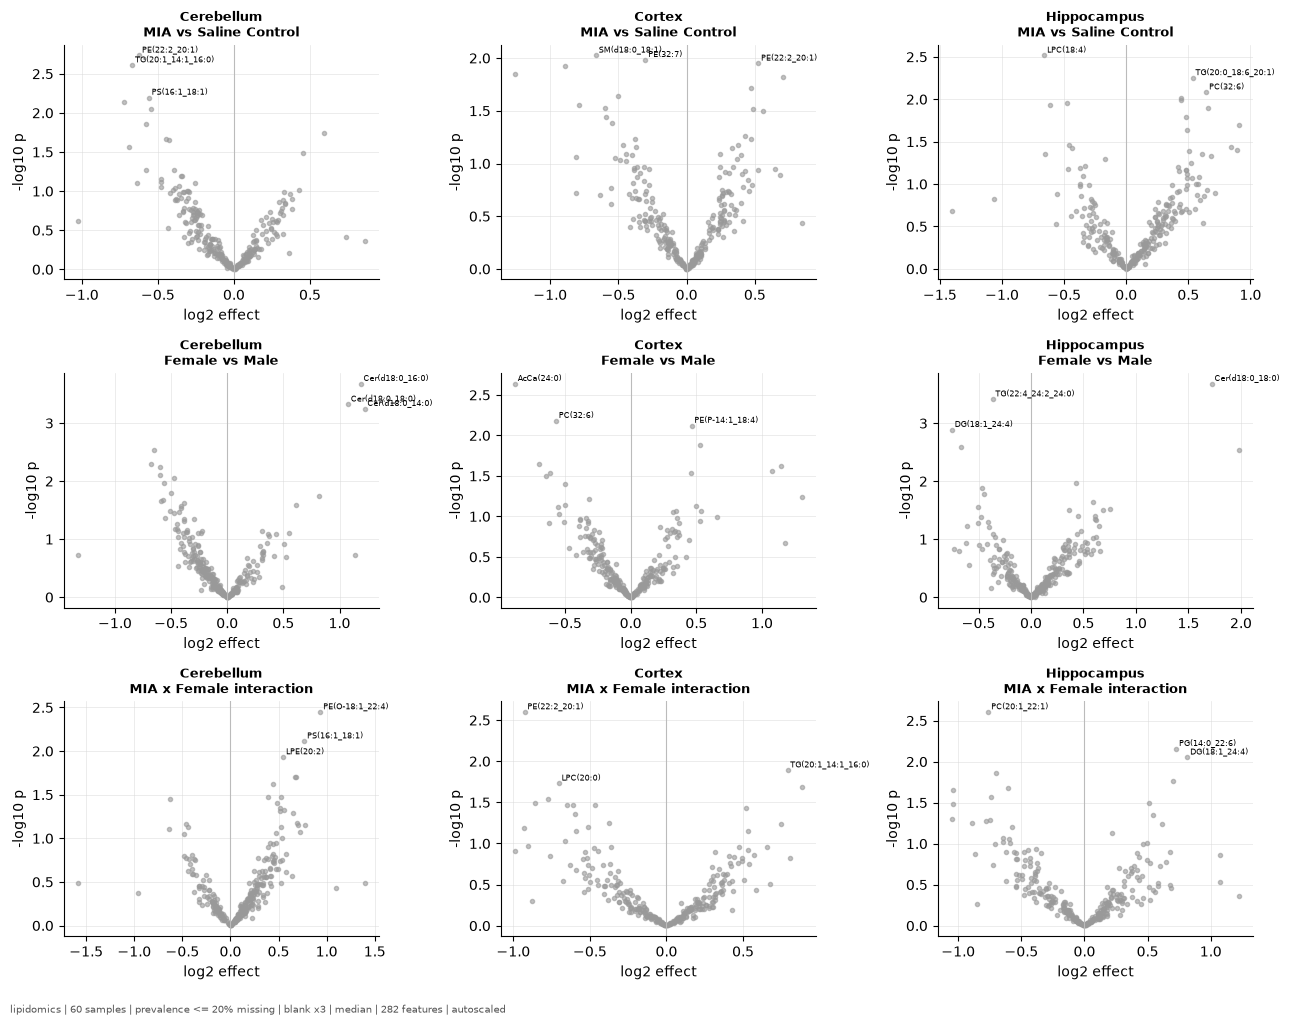

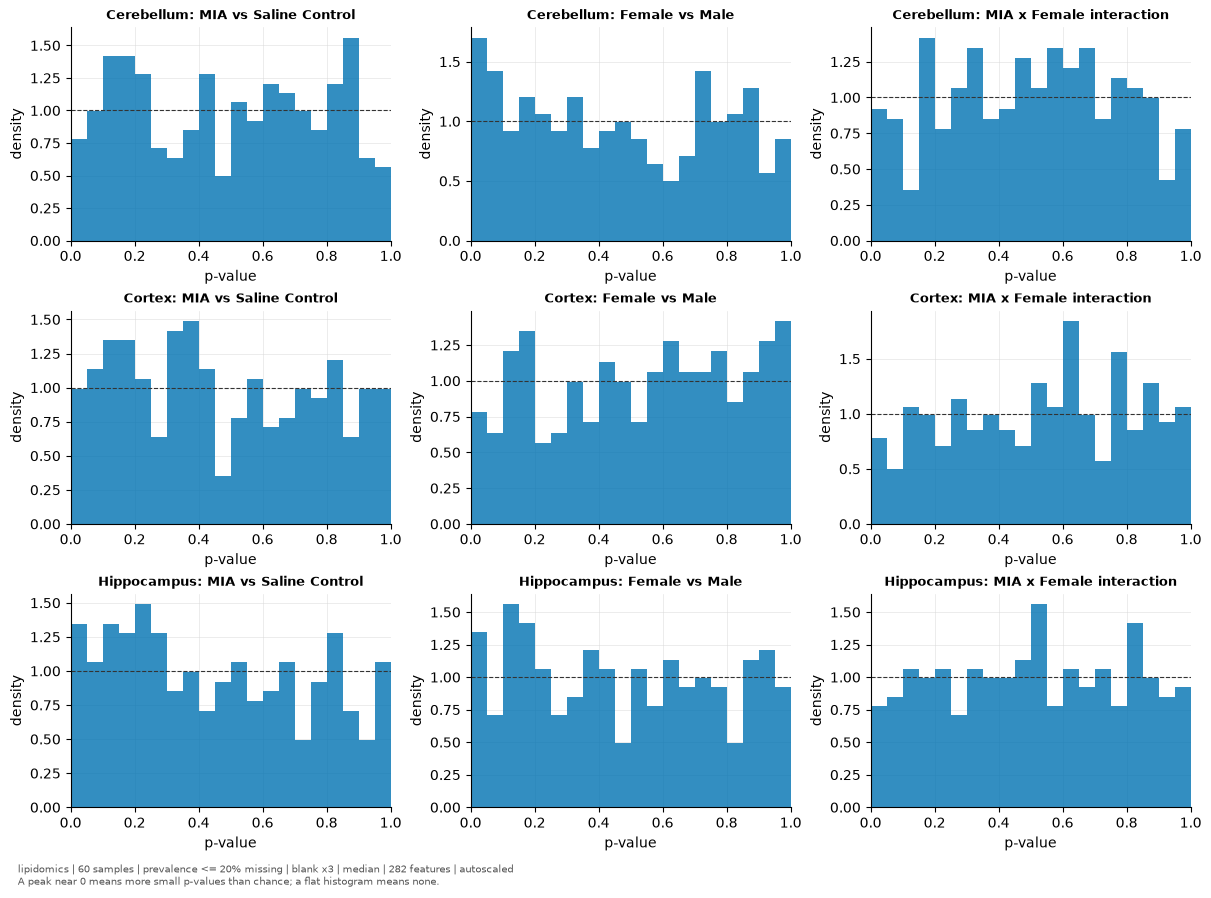

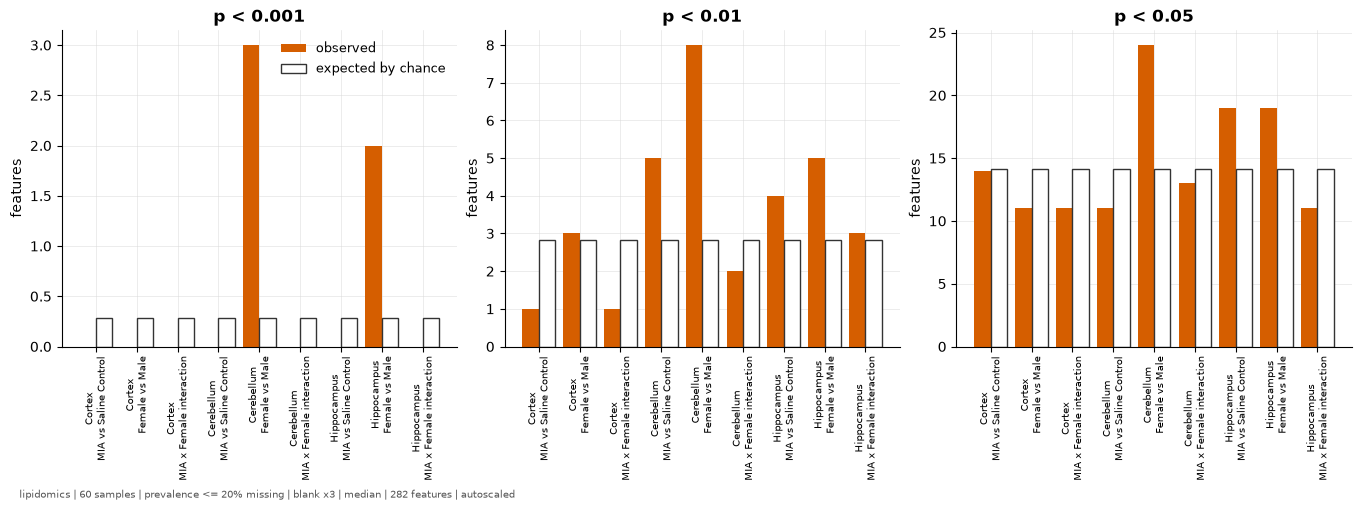

In [15]:
draw(explore.volcano, view, REGION, EFFECT)
draw(explore.volcano_grid, view)
draw(explore.p_value_histograms, view)
draw(explore.small_p_counts, view)

,Region,Effect,Feature,Label,Class,estimate_log2,ci_lower_log2,ci_upper_log2,p_value,p_value_fdr,n_usable
0,Cerebellum,MIA vs Saline Control,PE(22:2_20:1),PE(22:2_20:1),PE,-0.623,-0.977,-0.268,0.002,0.346,20
1,Cerebellum,MIA vs Saline Control,TG(20:1_14:1_16:0),TG(20:1_14:1_16:0),TG,-0.668,-1.062,-0.273,0.002,0.346,20
2,Cerebellum,MIA vs Saline Control,PS(16:1_18:1),PS(16:1_18:1),PS,-0.559,-0.937,-0.181,0.006,0.509,20
3,Cerebellum,MIA vs Saline Control,Hex2Cer(d18:0_18:1),Hex2Cer(d18:0_18:1),Hex2Cer,-0.720,-1.216,-0.223,0.007,0.509,20
4,Cerebellum,MIA vs Saline Control,FA(17:0),FA(17:0),FA,-0.543,-0.931,-0.155,0.009,0.509,20
5,Cortex,MIA vs Saline Control,SM(d18:0_18:1),SM(d18:0_18:1),SM,-0.664,-1.142,-0.187,0.009,0.713,20
6,Cortex,MIA vs Saline Control,PE(32:7),PE(32:7),PE,-0.302,-0.523,-0.081,0.010,0.713,20
7,Cortex,MIA vs Saline Control,PE(22:2_20:1),PE(22:2_20:1),PE,0.525,0.136,0.913,0.011,0.713,20
8,Cortex,MIA vs Saline Control,SM(d18:1_14:0),SM(d18:1_14:0),SM,-0.891,-1.556,-0.226,0.012,0.713,20
9,Cortex,MIA vs Saline Control,Cer(d18:0_16:0),Cer(d18:0_16:0),Cer,-1.258,-2.229,-0.288,0.014,0.713,20


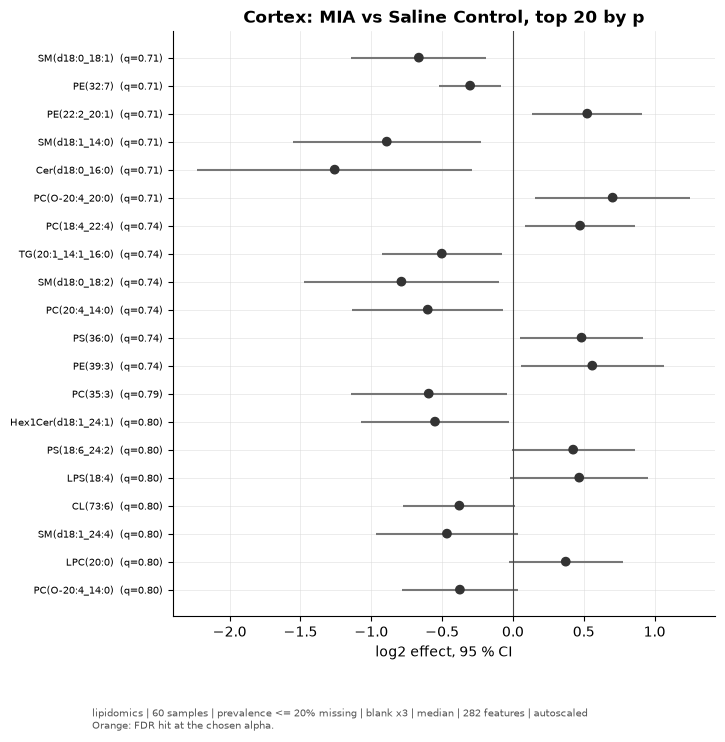

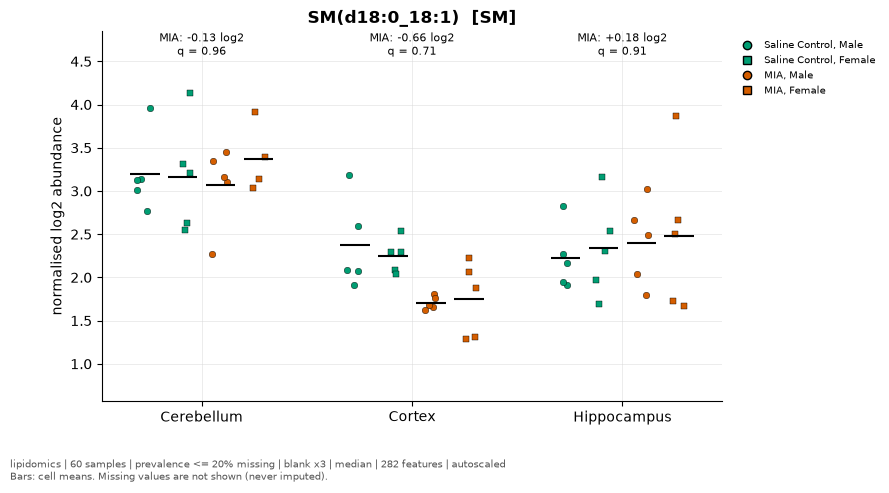

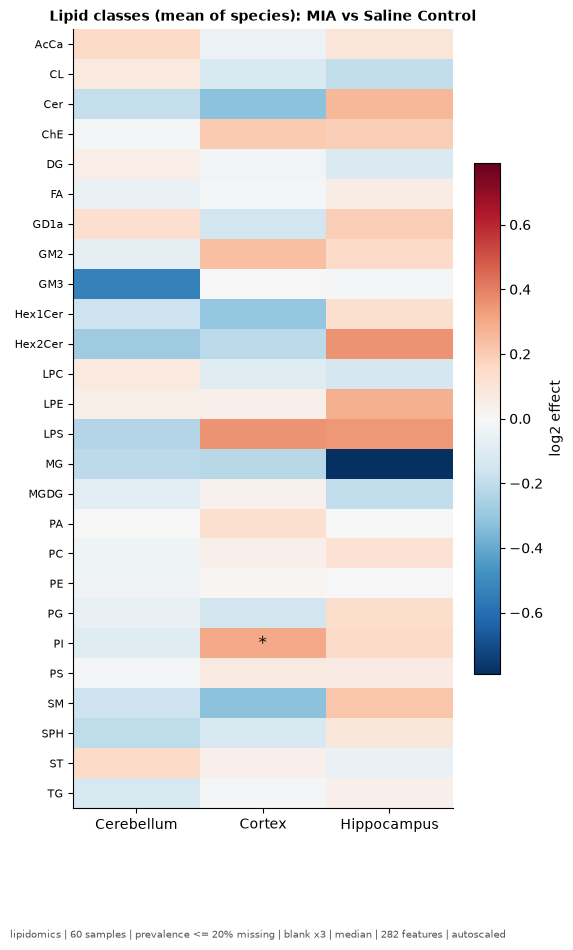

In [16]:
display(explore.top_hits(view, EFFECT, n=5))
draw(explore.effect_forest, view, REGION, EFFECT)
feature = FEATURE or explore.top_hits(view, EFFECT).query("Region == @REGION")["Feature"].iloc[0]
draw(explore.feature_profile, view, feature, EFFECT)
draw(explore.class_effects, view, EFFECT)

## 10. Feature space: co-abundance modules

Within one region (complete features only): how features correlate, whether
they form modules that survive bootstrapping, and whether the PCA loadings are
stable enough to interpret. In the study, structure is real (modules larger
than chance) but not resolvable with 20 samples per region.

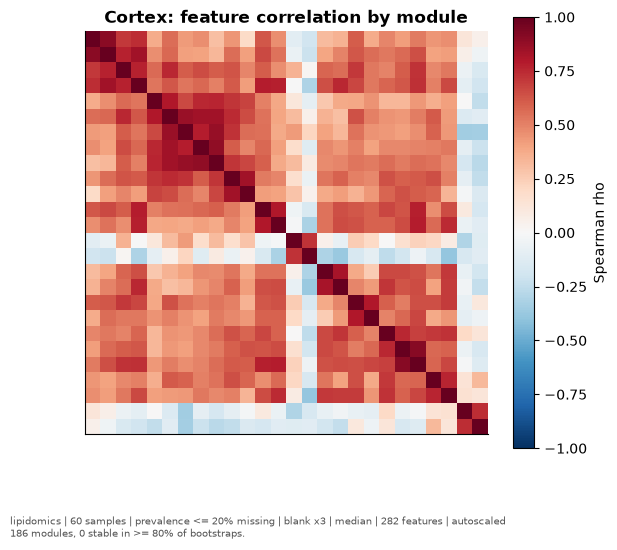

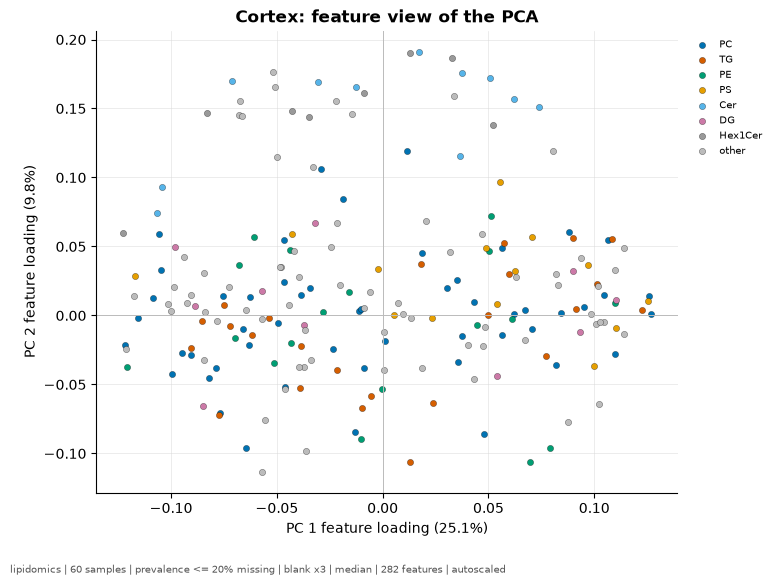

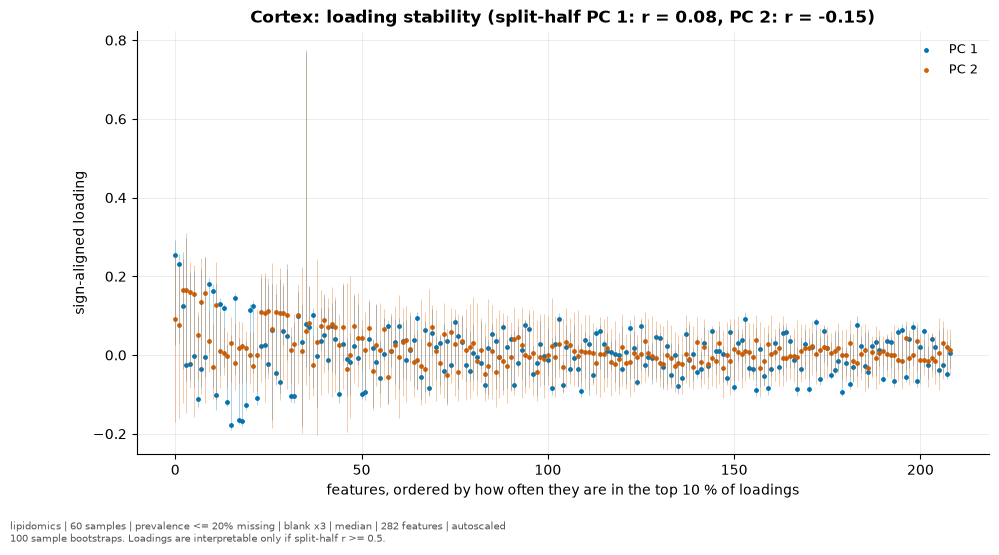

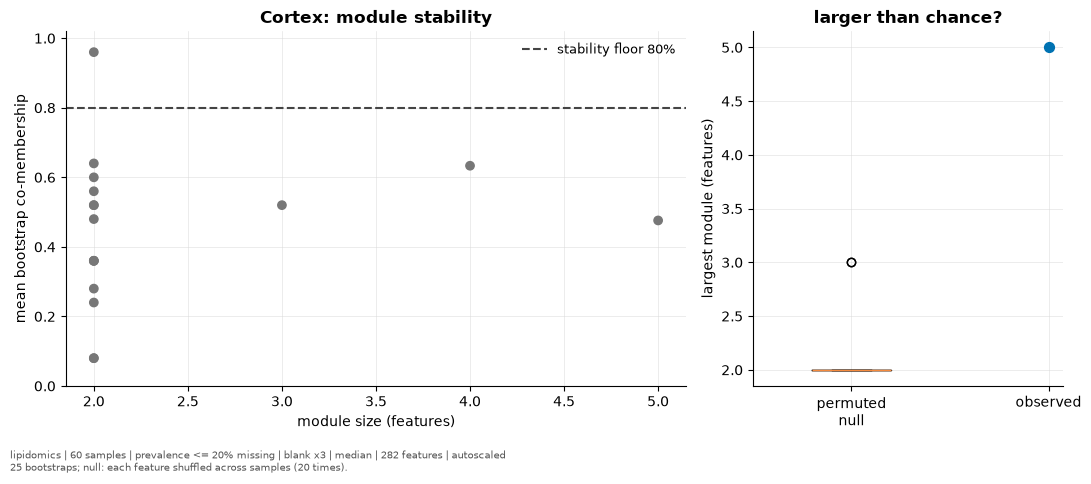

In [17]:
draw(explore.feature_correlation_heatmap, view, REGION)
draw(explore.feature_loadings_view, view, REGION)
draw(explore.feature_loading_stability, view, REGION)
draw(explore.module_stability, view, REGION)

## 11. Litters

Pups of one litter share a mother, cage and collection date, so they are not
independent. Do they cluster together in the PCA?

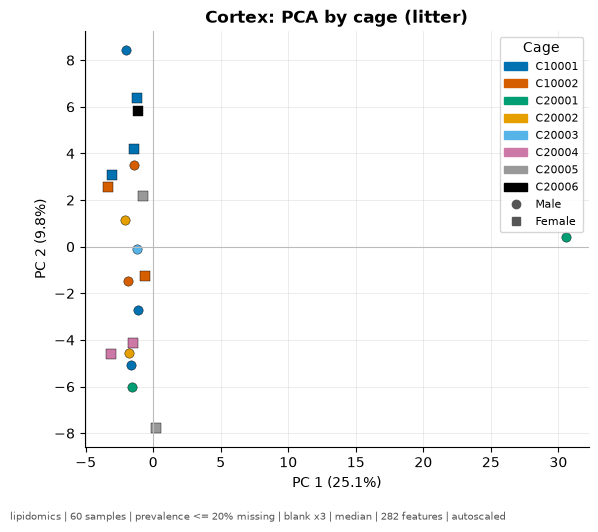

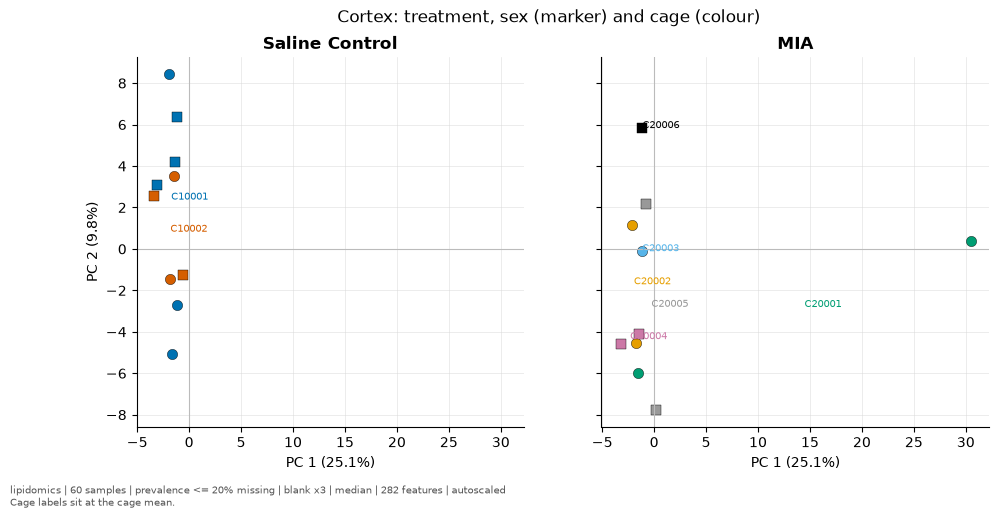

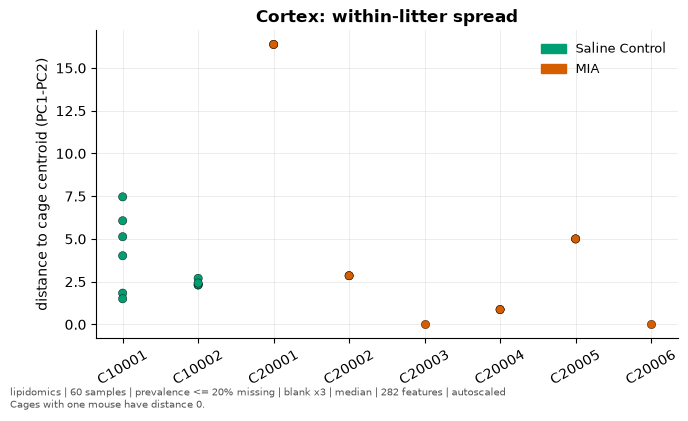

In [18]:
draw(explore.pca_by_cage, view, REGION)
draw(explore.cage_panels, view, REGION)
draw(explore.within_cage_distance, view, REGION)

## 12. Regional profiles: does MIA change how regions differ?

Every mouse gives all three regions, so each mouse is its own control. For each
region pair, every feature's mean within-mouse difference in controls is
plotted against the same difference in MIA mice. Points on the diagonal mean
the regional profile is unchanged.

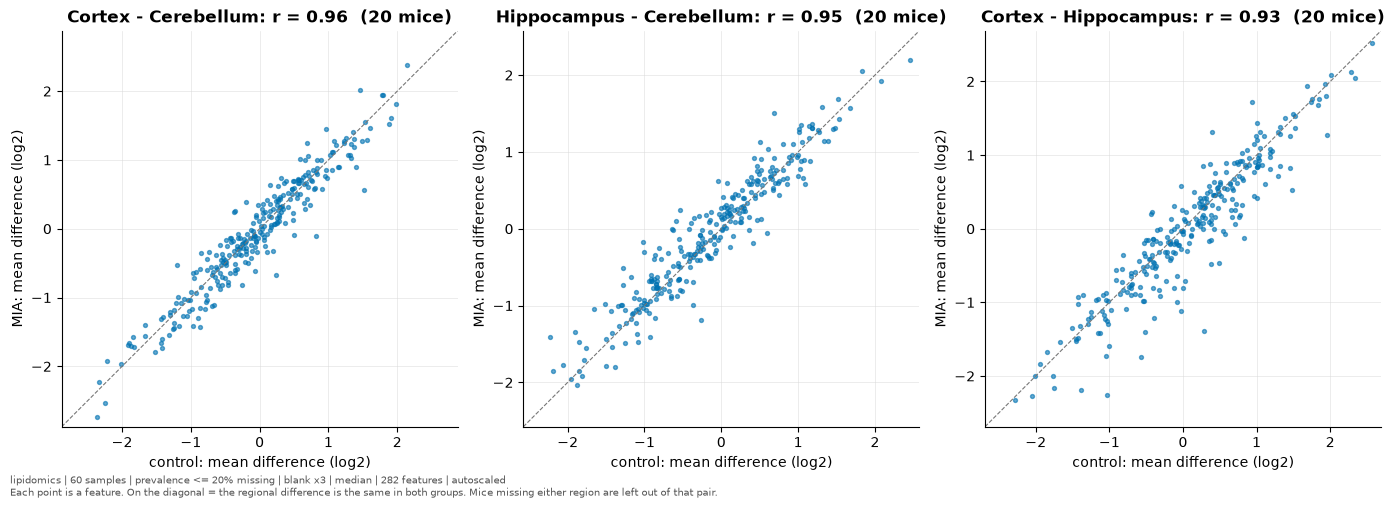

In [19]:
draw(explore.region_differences, view)

## 13. ASCA+

One multivariate ANOVA instead of hundreds of tests: the share of variance of
each model term, and the first score of selected effects. Permutation tests
for these shares are in the walkthrough (section 8).

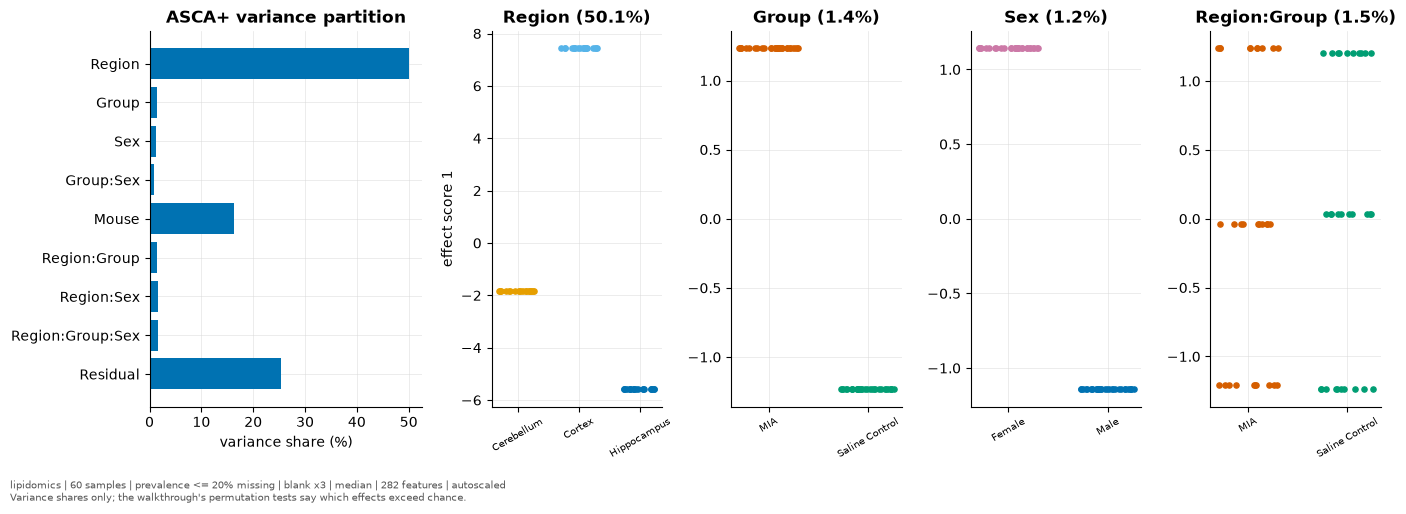

In [20]:
draw(explore.asca_overview, view)

## 14. Facility-style figures, every region

The core facility's report showed a heatmap of the top lipids and PLS-DA score
plots that seemed to separate MIA from control. Both are expected even with no
difference at all, which the permutation null next to each score plot shows.

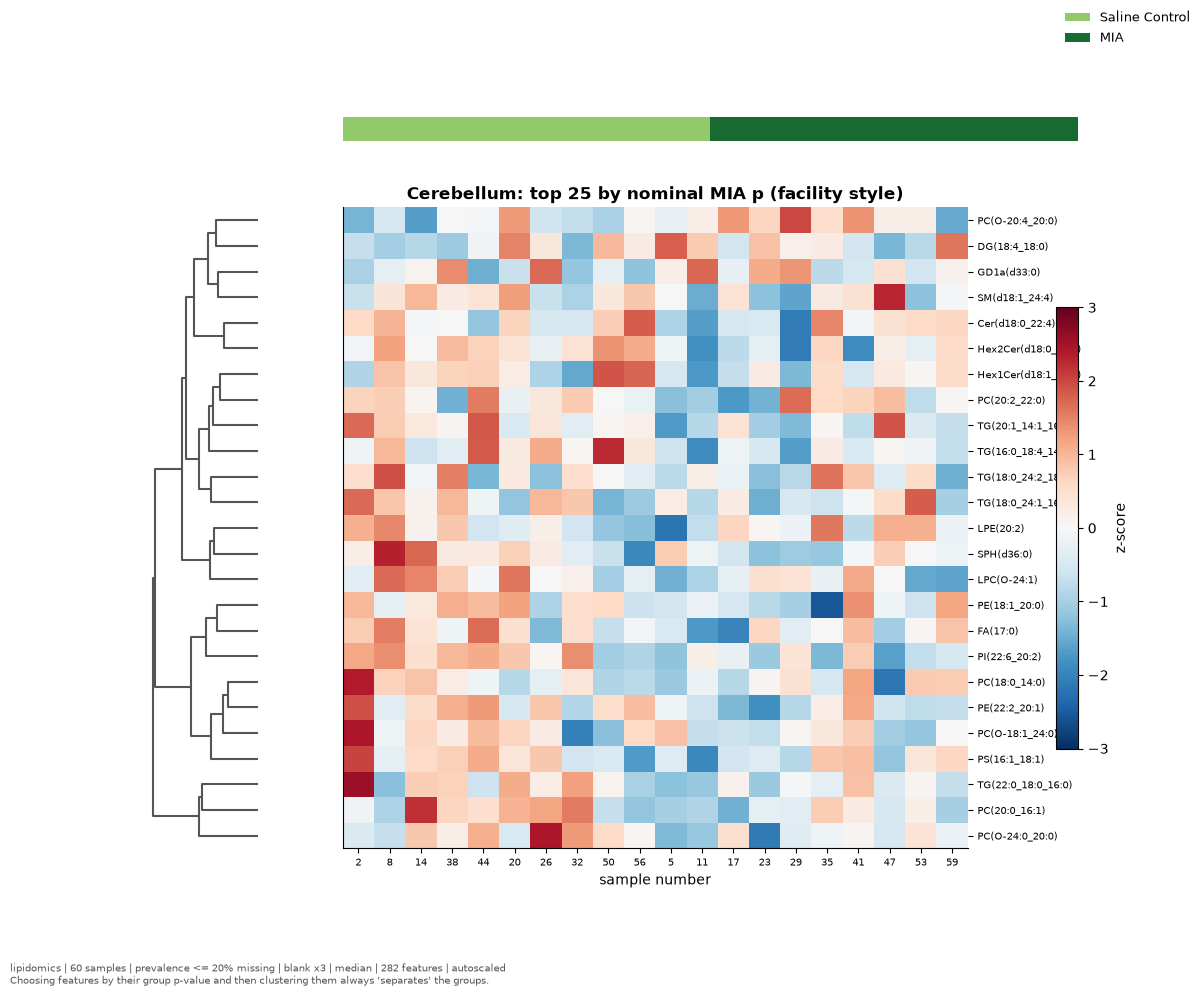

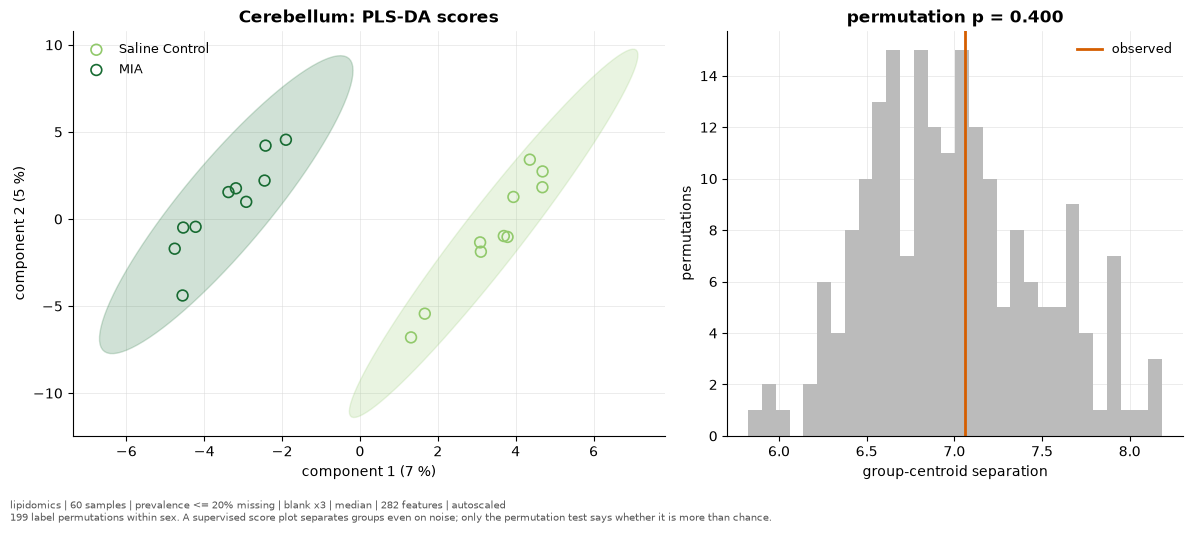

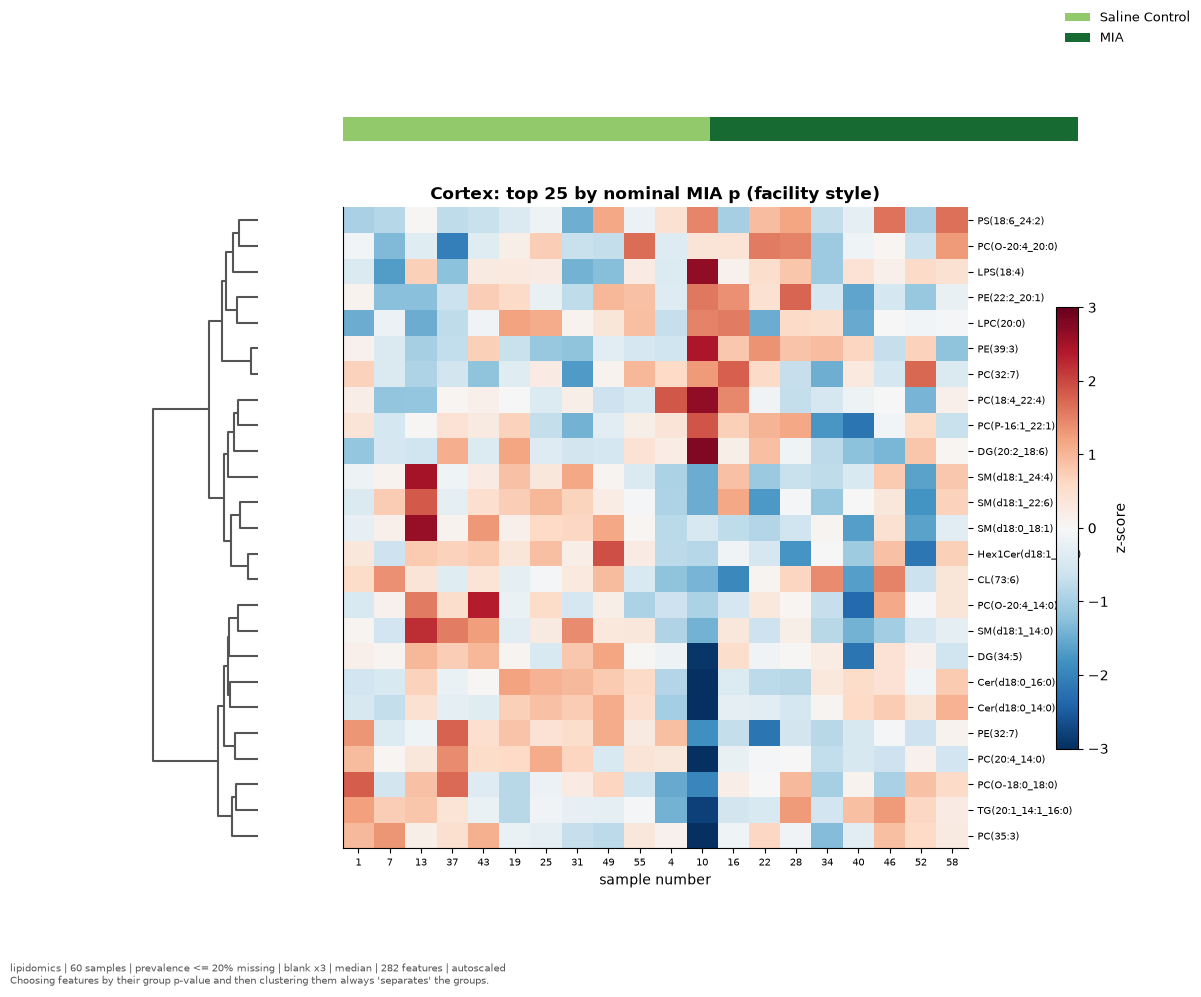

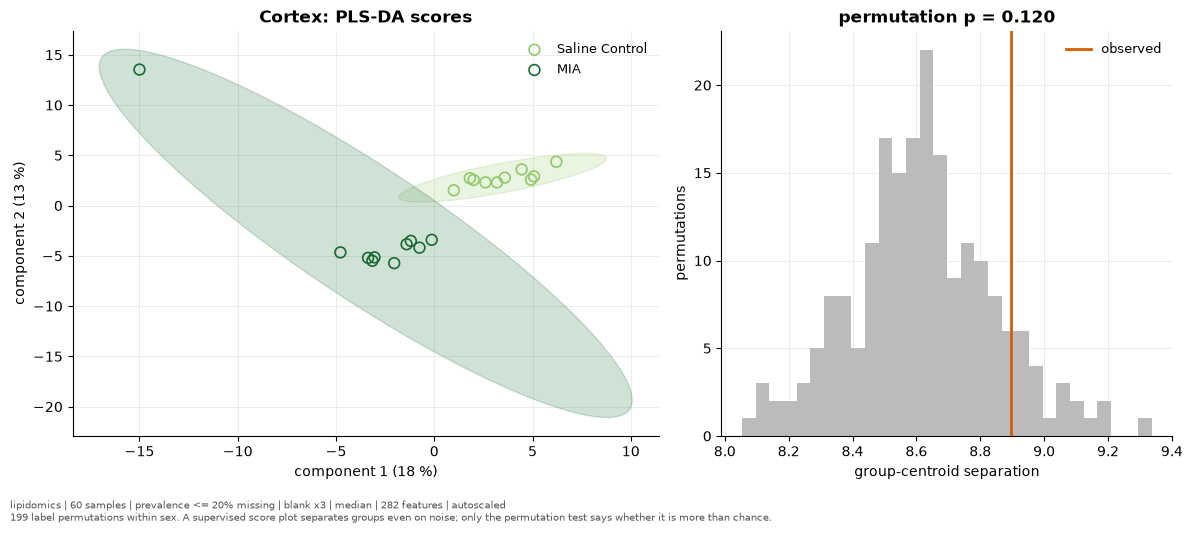

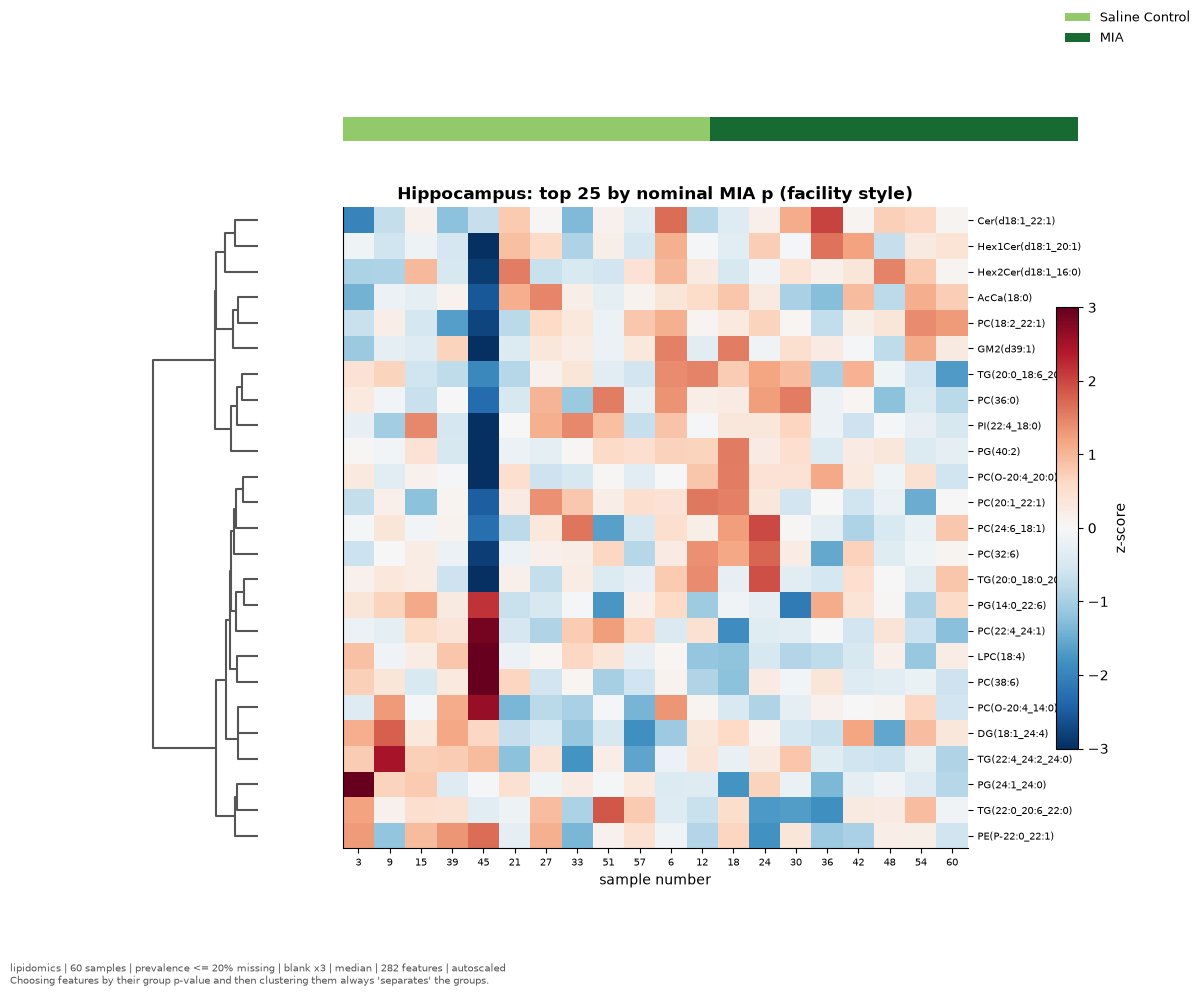

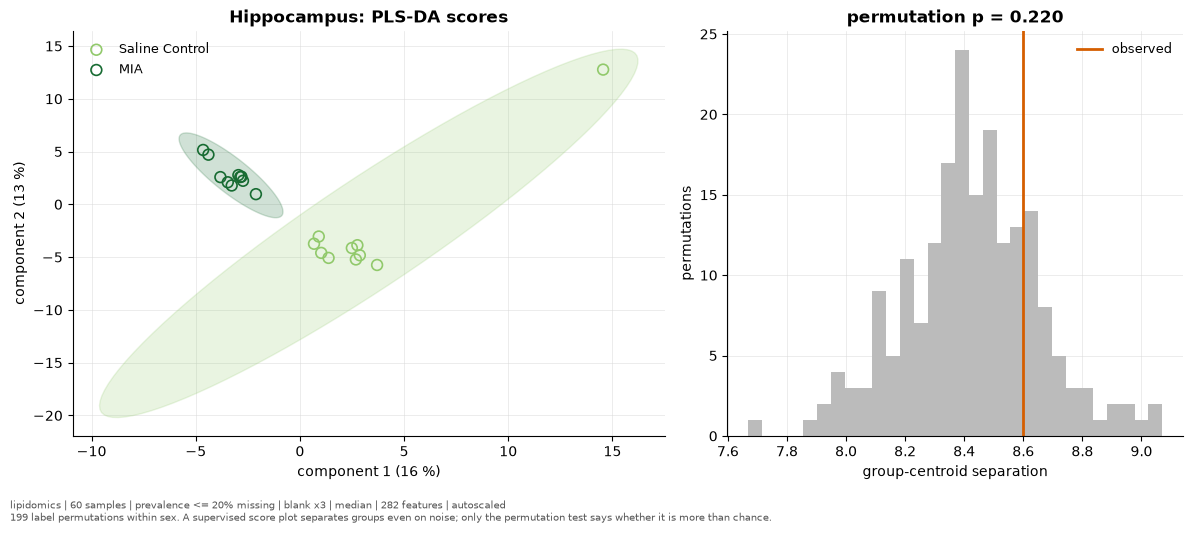

In [21]:
for region in config.REGIONS:
    draw(explore.vendor_heatmap, view, region)
    draw(explore.plsda_scores, view, region)

## 15. Lipid versus protein myelin signal

Mouse by mouse: the lipid myelin index (myelin lipids relative to other
glycerophospholipids) against the mean z-score of myelin structural proteins.
The same exclusions are applied to both assays.

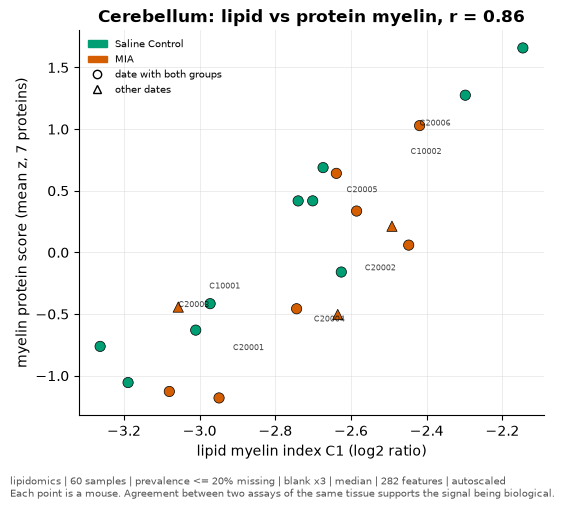

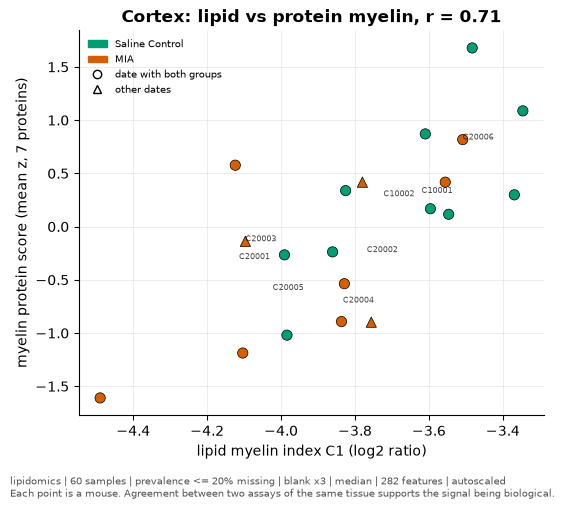

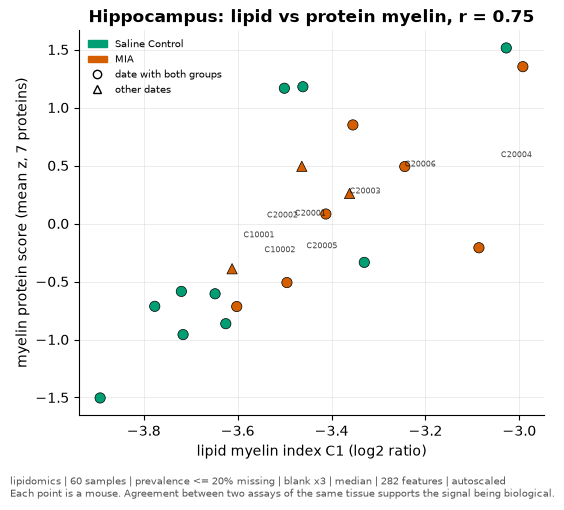

In [22]:
for region in config.REGIONS:
    draw(explore.myelin_lipid_vs_protein, view, region)

## 16. Saving the figures

With `SAVE_FIGURES = True`, every figure drawn above is written as a PNG into a
folder named after the settings.

In [23]:
run_name = "_".join([OMICS, f"{len(view.kept_samples)}samples",
                     "excl-" + "-".join(map(str, view.excluded_numbers())) if view.excluded else "all",
                     f"prev{MAX_MISSING_FRACTION}", f"blank{BLANK_MULTIPLIER:g}", NORMALIZATION, SCALING])
folder = settings.results_dir / "supplementary" / run_name
if SAVE_FIGURES:
    folder.mkdir(parents=True, exist_ok=True)
    for name, png in FIGURES.items():
        (folder / f"{name}.png").write_bytes(png)
    print(f"{len(FIGURES)} figures written to {folder.relative_to(PROJECT)}")
else:
    print(f"{len(FIGURES)} figures drawn; set SAVE_FIGURES = True to write them to {folder.relative_to(PROJECT)}")

73 figures written to results\supplementary\lipidomics_60samples_all_prev0.2_blank3_median_autoscaled
